# Phase 0: Preprocessing and quality control

We built paired single-cell pseudobulk and whole-blood bulk RNA-seq profiles from the raw AIFI Sound Life files (Gong et al., 2025) and measured how the two domains differ. From 2,586,999 subsampled peripheral blood cells in 868 samples and 836 bulk libraries, we obtained 836 same-draw pairs from 96 donors. These were normalized as log(1 + CP10k) on a 5,000-gene panel chosen on training donors only, and split by donor into train (582 pairs, 68 donors), validation (135 pairs, 14 donors) and test (119 pairs, 14 donors). The domain gap lies almost entirely on one axis: the first principal component of both domains together explains 82.0% of the variance, domain membership explains 99.0% of that component (η² = 0.990), and the domain silhouette is 0.777. Pairing carries sample-level signal, most of it shared across a donor's draws: the median centered correlation between a single-cell profile and its own bulk partner is 0.269, against 0.214 for other draws of the same donor and −0.003 for other donors. Whole-blood bulk also expresses granulocyte genes that PBMC pseudobulk lacks (2.26–2.77 log(1 + CP10k) units higher for five of seven genes), so single-cell → bulk translation has to generate signal that is absent from its input.

## 1. Aim

This phase turns the raw Sound Life files into the data every later phase uses, and describes the problem the translation models face. It asks three questions. How large is the gap between single-cell pseudobulk and whole-blood bulk, and how is it structured? How much sample-specific signal links a single-cell profile to the bulk profile of the same blood draw? Which biology is present in one domain and absent from the other? The answers bound what a translator trained without pairs can be expected to recover, and they fix the samples, genes and splits for all later comparisons.

## 2. Data

**Cohort.** The AIFI Sound Life study (Gong et al., 2025) followed healthy adults in two age groups, young (25–37 years) and older (55–67 years), with no donors aged 38–54, and drew blood at repeated visits. We use all 96 donors (49 young, 47 older), with a median of 10 paired draws per donor (range 1–10).

**Assays.** Each draw was profiled in two ways: single-cell RNA-seq of peripheral blood mononuclear cells (PBMC), with the provider's level-1 cell-type labels (AIFI_L1, 9 classes), and bulk RNA-seq of whole blood. PBMC isolation removes granulocytes, so the two assays measure different cell populations from the same draw.

**Data access.** The inputs are the study's public files on the AIFI data portal (doi:10.57785/bn17-3h16, CC BY 4.0):
- eight single-cell files, one per combination of age group, sex and cytomegalovirus (CMV) status, each reduced to a uniform random subsample of 3,000 cells per sample (every cell for samples with fewer), drawn before any quality control and kept as raw counts;
- the whole-blood bulk count file.

The subsample is defined by a fixed list of cell barcodes. `scripts/make_slims.py` rebuilds the eight subsampled files from the portal files and verifies each against a pinned content checksum (README, "Data"). This notebook reads the nine input files from `data/raw/soundlife/` and checks each against a pinned SHA-256 checksum.

**Samples and pairs.** There are 868 single-cell samples and 836 bulk sample kits. Every bulk kit has a single-cell sample from the same draw, which gives 836 pairs. The 32 single-cell samples without a bulk partner are not used.

**Splits and leakage boundaries.** Donors are split, grouped and stratified by age group, into train (582 pairs, 68 donors), validation (135 pairs, 14 donors) and test (119 pairs, 14 donors). The gene panel is chosen on training donors only. Normalization acts on each sample alone, and the quality-control thresholds were fixed in advance. Translation models are trained without pairs on two donor-disjoint halves of the training donors (§3.8); validation and test pairs are used only for evaluation. The descriptive statistics in §4.5, §4.7 and §4.9 use all 836 pairs; they characterize the data and feed no model or selection.

In [1]:
import hashlib, json, re, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import spearmanr

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())   # repo root, wherever this runs from
sys.path.insert(0, str(ROOT))

from dgm import paths
from dgm.data import load_pairs, save_pairs
from dgm.notebook import setup
from dgm.plotting import AGE, DOMAIN, INK, INK_2, LABELS, MUTED, SERIES, THRESHOLD, figure, panel_labels, save_show

info = setup(seed=0, notebook="phase0_preprocessing.ipynb")

RAW, PROC = paths.RAW, paths.PROCESSED
PROC.mkdir(parents=True, exist_ok=True)
FIG = paths.results_dir(0, "figures")
SLIMS = sorted(RAW.glob("*__slim.h5ad"))
BULK_FILE = RAW / "sound-life_whole-blood_no-stim.h5ad"

MIN_GENES = 200                 # per cell
MAX_PCT_MITO = 20.0             # per cell, percent
MIN_CELLS_PER_SAMPLE = 500      # post-QC cells a single-cell sample must keep
BULK_MIN_LIBRARY = 1_000_000
TARGET_SUM = 1e4
PANEL_SIZE = 5000
PANEL_MIN_DETECTED = 0.5        # fraction of training samples, required on both sides
SPLIT_FRACS = {"train": 0.70, "val": 0.15, "test": 0.15}
SPLIT_SEED = 20261004
CELLS_PER_SAMPLE_FOR_UMAP = 60
FORCE = False

def this_cell_sha(marker):
    """Hash of the source of the cell being run. Cache keys include the code that builds each
    file, so editing that code rebuilds the cache (no version number to remember to bump).
    *marker* is text the calling cell must contain: outside a normal cell execution (silent
    execution, %run of an exported script) the history entry is some other source, and this
    fails loudly instead of hashing the wrong code."""
    src = get_ipython().user_ns["_ih"][-1]
    assert marker in src, f"this_cell_sha: running cell's source not found (expected {marker!r}); run this notebook cell by cell"
    return hashlib.sha256(src.encode()).hexdigest()[:16]

def cached(path, params):
    """True if an h5ad cache exists and was built with exactly these params (stored in .uns:
    thresholds, raw checksums, gene axis, and the hash of the code that built it)."""
    if FORCE or not path.exists():
        return False
    stored = ad.read_h5ad(path, backed="r")
    ok = stored.uns.get("params") == json.dumps(params, sort_keys=True)
    built_with = stored.uns.get("built_with", "unknown")
    stored.file.close()
    print(f"{path.name}: " + (f"reusing (built at commit {built_with})" if ok else "built with different params or code, rebuilding"))
    return ok

def cache_uns(params):
    """What every cache stores: the params that key it, and the commit it was built at (provenance only)."""
    return {"params": json.dumps(params, sort_keys=True), "built_with": info["commit"]}

def show_caption(name):
    """Show a saved figure's caption, read from results/phase0/figures/captions.md (keyed by file name)."""
    text = (FIG / "captions.md").read_text()
    display(Markdown(text.split(f"\n## {name}\n", 1)[1].split("\n## ", 1)[0].strip()))

# SHA-256 of each raw input file (the eight single-cell subsamples rebuilt by scripts/make_slims.py, and the bulk file)
PINNED_SHA256 = {
    "SoundLife_YoungAdult_Male_CMVpos__slim.h5ad": "c69c7c0c3627960d72ba1c045aa9657fe77985ae9ca8c004c2a1d502046cb403",
    "SoundLife_YoungAdult_Male_CMVneg__slim.h5ad": "4388659968a9443a9f5b14d1d7d7cb4df37393642c20ab05e70b988e2439676f",
    "SoundLife_YoungAdult_Female_CMVpos__slim.h5ad": "5d50358a4ccaaaf800b0770fb445561e0dc226fe39be113b00937c1a2cae7def",
    "SoundLife_YoungAdult_Female_CMVneg__slim.h5ad": "1679271602877b2aa6f96e198e119e6dbeceabcf651261b0c915bef779dace30",
    "SoundLife_OlderAdult_Male_CMVpos__slim.h5ad": "11d0d192bbb7c10af2c97ded674da6d7cf051cd3c135b50a09944243025cf27f",
    "SoundLife_OlderAdult_Male_CMVneg__slim.h5ad": "f273d2b0fee9255f5e0567f1a7d3ecb87369dc3d3b017ed35313cf0d749b935a",
    "SoundLife_OlderAdult_Female_CMVpos__slim.h5ad": "f273d45b4a244b3070148a56fe2dd26a840f1863809c78904b5c01311e869b98",
    "SoundLife_OlderAdult_Female_CMVneg__slim.h5ad": "adb1be7cde3f01a8449aa5895a9f6c6e67c8111956be8894e95f9693bbad19e1",
    "sound-life_whole-blood_no-stim.h5ad": "980d39ca002d1fd18c0e7cb6d658602d8395e1cf7fe8a2fac069b12bfb7d71e9",
}
print(len(SLIMS), "slims;", "bulk present:", BULK_FILE.exists())

commit: 925d4bc | notebook_source: a7e3614abaee (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: True
8 slims; bulk present: True


The setup cell above fixes the thresholds and seeds and prints the commit the notebook ran on. The next cell checks the nine raw input files against their pinned checksums.

In [2]:
sys.path.insert(0, str(ROOT / "scripts"))
from make_slims import CONTENT_SHA256, content_checksum   # content checksums of the eight subsamples

def sha256(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

# Hashing ~28 GB takes ~1-2 min; cache by (size, mtime) so reruns skip it.
cache_path = PROC / "raw_checksums.json"
cache = json.loads(cache_path.read_text()) if cache_path.exists() else {}
for path in [*SLIMS, BULK_FILE]:
    real = path.resolve()
    key = f"{real.stat().st_size}:{real.stat().st_mtime_ns}"
    if cache.get(path.name, {}).get("key") != key:
        cache[path.name] = {"key": key, "sha256": sha256(real)}
    if cache[path.name]["sha256"] != PINNED_SHA256[path.name]:
        # A single-cell subsample rebuilt by scripts/make_slims.py has the same content but may be written with different
        # bytes (h5ad library version). Accept it if its content checksum matches the pinned one.
        assert path.name in CONTENT_SHA256, f"{path.name}: checksum differs from the pinned value"
        cache[path.name]["content_sha256"] = cache[path.name].get("content_sha256") or content_checksum(ad.read_h5ad(real))
        assert cache[path.name]["content_sha256"] == CONTENT_SHA256[path.name], f"{path.name}: content differs from the pinned value"
cache_path.write_text(json.dumps(cache, indent=1))
assert len(SLIMS) == 8
print("all 9 raw files match their pinned checksums (file bytes, or for a rebuilt subsample, content)")

all 9 raw files match their pinned checksums (file bytes, or for a rebuilt subsample, content)


## 3. Methods

### 3.1 Gene names
The provider made repeated gene symbols in the single-cell feature list unique by appending "-1", "-2", and so on. We strip the suffix when the base symbol is also present and the suffixed name is not itself a symbol in the bulk annotation, then sum the counts of features that share a symbol. Non-gene features (names beginning with "__" or "ERCC-") are dropped.

### 3.2 Cell quality control
A cell passes if it has at least 200 genes detected and less than 20% of its counts from the 13 mitochondrial genes. Genes detected are counted on the raw feature list, before same-symbol features are merged. A sample is kept if at least 500 of its cells pass.

### 3.3 Pseudobulk and composition
The pseudobulk profile of a sample is the sum of the raw counts of all its passing cells (up to 3,000). The measured composition $c^*$ of a sample is the fraction of its passing cells in each AIFI_L1 class, computed from the same cells. The 9 classes are merged into 6 targets: T cells (T), monocytes (Mono), B cells (B), natural killer cells (NK), dendritic cells (DC), and "Other", which pools the four classes that each make up less than 0.5% of cells (platelets, erythrocytes, progenitor cells and innate lymphoid cells). These fractions are relative to PBMC. For a bulk sample, $c^*$ is therefore the composition of the mononuclear fraction of the same draw, not of whole blood, which also contains granulocytes.

### 3.4 Bulk processing
Two sample kits were sequenced twice; the libraries of each are summed. Libraries with fewer than 1 million counts would be dropped. For quality control we also record each library's genes detected and its mitochondrial and globin count fractions.

### 3.5 Pairing
A pair is one blood draw: the single-cell sample identifier and the bulk sample-kit identifier are the same key. Donor, age at draw, sex, CMV status and visit must agree between the two sides. A draw belongs to the older group if the donor's age at draw is 55 or more; this agrees with the provider's age-group label on both sides.

### 3.6 Normalization
Both domains are normalized the same way, as log(1 + CP10k) over the genes measured in both:

$$x_g = \log\Bigl(1 + 10^4 \, \frac{n_g}{\sum_{g' \in G} n_{g'}}\Bigr),$$

where $n_g$ is the raw count of gene $g$ in a sample and $G$ is the set of 32,965 genes shared by the single-cell and bulk annotations. Taking the library size over the same gene set gives both domains the same denominator.

### 3.7 Gene panel
The panel is chosen on the training donors only. Candidate genes are those detected (count above 0) in at least 50% of training samples in both domains. Within each domain we rank the candidates by normalized dispersion (the Seurat flavor of highly variable gene selection in scanpy [Wolf et al., 2018], 20 mean bins), average the two ranks, and keep the top 5,000 genes, breaking ties by gene symbol. The model-ready profiles are the log(1 + CP10k) values of these 5,000 genes.

### 3.8 Donor split and training halves
The split is donor-grouped and age-stratified: within each age group, donors are permuted with a fixed seed and assigned 15% to test, 15% to validation and the rest to train, so all draws of a donor fall in one split. For training without pairs, the 68 training donors are further divided into two donor-disjoint halves. Half A supplies only single-cell profiles and half B only bulk profiles, so no pair is ever seen together during training. Donors are shuffled within each age group and each is assigned to the half with fewer draws so far, which balances the halves in age mix and number of draws. Halving 0 is the primary division; halving 1 checks how much results depend on it.

### 3.9 Statistics describing the domain gap
- **Principal components.** We fit a principal component analysis (PCA) to the 1,672 panel profiles of both domains together (836 per domain) and keep the top 10 principal components (PCs).
- **η².** For a PC and a grouping (domain or age group), η² is the between-group sum of squares divided by the total sum of squares: the share of that PC's variance explained by the grouping.
- **Domain silhouette.** The mean silhouette width of the domain labels in the space of the top 10 PCs (Euclidean distance). It is 1 when the domains are perfectly separated and near 0 when they overlap.
- **Centered correlation.** We subtract each domain's per-gene mean over the 836 samples and take the cosine similarity between a centered single-cell profile and a centered bulk profile. We compare three kinds of profile pairs: a sample's own pair, other draws of the same donor, and draws of other donors. The **partner rank** of a single-cell profile is the rank of its own bulk partner among all 836 bulk profiles by centered correlation (1 = best match).
- **Marker–composition agreement.** The Spearman rank correlation ρ, across the 836 pairs, between a marker gene's log(1 + CP10k) expression and the measured fraction of its lineage, computed separately in each domain. Markers are taken from all shared genes, not only the panel.
- **Within-donor share of composition variance.** For each class, the sum over draws of squared deviations from the donor's mean fraction, divided by the sum of squared deviations from the overall mean.

### 3.10 Integrity checks
The notebook asserts that:
- every feature has a gene symbol and counts are non-negative integers;
- each subsample holds exactly min(3,000, all cells) of its sample;
- there are 868 single-cell samples, 836 bulk kits and 96 donors on both sides, and the metadata of every pair agree;
- T cells are the most abundant class;
- quality control removes less than 10% of any major lineage and shifts no mean class fraction by more than 2 percentage points;
- the bulk globin fraction stays below 5%;
- our normalization equals scanpy's total-count normalization followed by log(1 + x);
- the panel is unchanged when the expression values of validation and test donors are permuted across genes, so no held-out information enters the panel.

## 4. Results

### 4.1 Quality control

**Every cell, single-cell sample and bulk library passed quality control.** The next three cells build the gene axis, the single-cell pseudobulk and composition, and the summed bulk libraries (each reused from its cache when the inputs and code are unchanged). The cell after them checks pass rates, the effect of quality control on composition, and the number of cells per sample.

In [3]:
GENE_AXIS_CODE = this_cell_sha("GENE_AXIS_CODE =")   # the gene-name and collapse rules; part of every cache key
bulk_raw = ad.read_h5ad(BULK_FILE)
BULK_SYMBOLS = pd.Index(bulk_raw.var_names.astype(str))
assert BULK_SYMBOLS.is_unique

def assert_symbols(symbols, what):
    # No missing/empty/"nan" feature names: they would all be summed into one fake gene (a check from an earlier pipeline).
    s = pd.Series(list(symbols), dtype=object)
    assert s.notna().all() and not s.astype(str).str.strip().isin(["", "nan", "NaN", "None", "N/A", "NA"]).any(), \
        f"{what}: a feature has no gene symbol"

assert_symbols(BULK_SYMBOLS, "bulk")

def is_gene(symbols):
    s = pd.Index(symbols).astype(str)
    return ~(s.str.startswith("__") | s.str.startswith("ERCC-"))

def restore_names(names, known):
    # Strip "-N" where the base symbol is also present and the suffixed name isn't a known symbol.
    names = [str(n) for n in names]
    present, known = set(names), set(known)
    out = []
    for n in names:
        base = re.sub(r"-\d+$", "", n)
        out.append(base if base != n and base in present and n not in known else n)
    return pd.Index(out)

def collapse_matrix(symbols, genes):
    # features x genes 0/1 matrix: summing columns that share a symbol, dropping non-genes.
    symbols = pd.Index(symbols)
    keep = np.flatnonzero(is_gene(symbols))
    target = genes.get_indexer(symbols[keep])
    assert (target >= 0).all()
    return sp.csr_matrix((np.ones(len(keep), dtype=np.int64), (keep, target)), shape=(len(symbols), len(genes)))

sc_features = None
for path in SLIMS:
    v = pd.Index(ad.read_h5ad(path, backed="r").var_names.astype(str))
    assert sc_features is None or v.equals(sc_features), f"{path.name}: feature list differs from the other slims"
    sc_features = v
assert_symbols(sc_features, "single-cell")
sc_symbols = restore_names(sc_features, BULK_SYMBOLS)
SC_GENES = pd.Index(sorted(set(sc_symbols[is_gene(sc_symbols)])))
SC_COLLAPSE = collapse_matrix(sc_symbols, SC_GENES)
MITO_FEATURES = np.flatnonzero(sc_features.str.startswith("MT-"))
print(f"single-cell: {len(sc_features)} features -> {len(SC_GENES)} genes "
      f"({(sc_symbols != sc_features).sum()} suffixes restored); {len(MITO_FEATURES)} MT- features")
assert len(MITO_FEATURES) == 13
merged = pd.Series(sc_symbols[is_gene(sc_symbols)]).value_counts()
print(f"{(merged > 1).sum()} single-cell symbols carry several features (counts summed): {merged[merged > 1].to_dict()}")

single-cell: 33538 features -> 33514 genes (24 suffixes restored); 13 MT- features
24 single-cell symbols carry several features (counts summed): {'PDE11A': 2, 'SCO2': 2, 'LINC01505': 2, 'PRSS50': 2, 'ATXN7': 2, 'EMG1': 2, 'CYB561D2': 2, 'LINC01238': 2, 'CCDC39': 2, 'TXNRD3NB': 2, 'ABCF2': 2, 'HSPA14': 2, 'TBCE': 2, 'SOD2': 2, 'RGS5': 2, 'TMSB15B': 2, 'MATR3': 2, 'PINX1': 2, 'POLR2J3': 2, 'DIABLO': 2, 'LINC02203': 2, 'IGF2': 2, 'H2BFS': 2, 'COG8': 2}


In [4]:
SAMPLE_META = ["donor_id", "numeric", "age_group", "sex", "cmv", "timepoint", "batch_id", "n_cells_full"]
pb_path, qc_path, cells_path = PROC / "sc_pseudobulk_counts.h5ad", PROC / "sc_cell_qc.h5ad", PROC / "sc_cell_sample.h5ad"

def sample_rng(sample_id):
    return np.random.default_rng(int.from_bytes(hashlib.sha256(sample_id.encode()).digest()[:8], "little"))

SC_PARAMS = {"code": [GENE_AXIS_CODE, this_cell_sha("SC_PARAMS =")], "min_genes": MIN_GENES, "max_pct_mito": MAX_PCT_MITO, "cells_per_sample_for_umap": CELLS_PER_SAMPLE_FOR_UMAP,
             "sc_genes_sha256": hashlib.sha256("\n".join(SC_GENES).encode()).hexdigest(), "raw": {p.name: cache[p.name]["sha256"] for p in SLIMS}}
if not all(cached(p, SC_PARAMS) for p in (pb_path, qc_path, cells_path)):
    qc_tables, sums, metas, cell_X, cell_obs = [], [], [], [], []
    for path in SLIMS:
        t0 = time.time()
        a = ad.read_h5ad(path)
        X = sp.csr_matrix(a.X)
        X.eliminate_zeros()
        assert X.data.min() >= 0 and np.array_equal(X.data, np.round(X.data)), f"{path.name}: not non-negative integer counts"
        obs = a.obs
        qc = pd.DataFrame({
            "sample_id": obs["sample_id"].astype(str).to_numpy(),
            "AIFI_L1": obs["AIFI_L1"].astype(str).to_numpy(),
            "AIFI_L2": obs["AIFI_L2"].astype(str).to_numpy(),
            "genes_detected": np.diff(X.indptr),
            "total_counts": np.asarray(X.sum(axis=1, dtype=np.int64)).ravel(),
            "mito_counts": np.asarray(X[:, MITO_FEATURES].sum(axis=1, dtype=np.int64)).ravel(),
        }, index=obs.index.astype(str))
        qc["pct_mito"] = 100 * qc["mito_counts"] / qc["total_counts"].clip(lower=1)
        qc["passed_qc"] = (qc["genes_detected"] >= MIN_GENES) & (qc["pct_mito"] < MAX_PCT_MITO)
        qc["file"] = path.name
        # per-sample sums over passing cells: (samples x cells indicator) @ X
        samples = pd.Index(pd.unique(qc["sample_id"]))
        rows = samples.get_indexer(qc["sample_id"])
        passing = qc["passed_qc"].to_numpy()
        S = sp.csr_matrix((np.ones(passing.sum(), dtype=np.int64), (rows[passing], np.flatnonzero(passing))),
                          shape=(len(samples), X.shape[0]))
        sums.append(np.asarray((S @ X @ SC_COLLAPSE).todense()))
        meta = obs.assign(sample_id=obs["sample_id"].astype(str)).groupby("sample_id", observed=True)[SAMPLE_META]
        assert (meta.nunique() == 1).all().all(), f"{path.name}: sample metadata varies within a sample"
        metas.append(meta.first().loc[samples].assign(file=path.name))
        qc_tables.append(qc)
        # A seeded random sample of passing cells per sample, for the cell-level UMAP only.
        for sid in samples:
            rows_s = np.flatnonzero((qc["sample_id"].to_numpy() == sid) & passing)
            pick = np.sort(sample_rng(sid).choice(rows_s, min(CELLS_PER_SAMPLE_FOR_UMAP, len(rows_s)), replace=False))
            cell_X.append((X[pick] @ SC_COLLAPSE).astype(np.int32))
            cell_obs.append(qc.iloc[pick][["sample_id", "AIFI_L1", "AIFI_L2"]])
        print(f"{path.name}: {X.shape[0]} cells, {len(samples)} samples, {passing.mean():.1%} pass QC, {time.time() - t0:.0f}s", flush=True)
        del a, X, S

    cell_qc = pd.concat(qc_tables)
    assert cell_qc.index.is_unique
    for c in ("sample_id", "AIFI_L1", "AIFI_L2", "file"):
        cell_qc[c] = cell_qc[c].astype("category")
    ad.AnnData(obs=cell_qc, uns=cache_uns(SC_PARAMS)).write_h5ad(qc_path)

    sc_meta = pd.concat(metas)
    assert sc_meta.index.is_unique, "a sample spans two slim files"
    passed = cell_qc[cell_qc["passed_qc"]]
    sc_meta["n_cells_slim"] = cell_qc.groupby("sample_id", observed=True).size().reindex(sc_meta.index)
    sc_meta["n_cells_pass"] = passed.groupby("sample_id", observed=True).size().reindex(sc_meta.index).fillna(0).astype(int)
    comp = pd.crosstab(passed["sample_id"].astype(str), passed["AIFI_L1"].astype(str))
    comp = comp[comp.sum().sort_values(ascending=False).index]
    comp = comp.div(comp.sum(axis=1), axis=0).reindex(sc_meta.index).fillna(0)
    sc_meta = sc_meta.join(comp.add_prefix("frac_"))
    for c in sc_meta.columns:
        if sc_meta[c].dtype == object or str(sc_meta[c].dtype) == "category":
            sc_meta[c] = sc_meta[c].astype(str)
    ad.AnnData(sp.csr_matrix(np.vstack(sums)), obs=sc_meta, var=pd.DataFrame(index=SC_GENES),
               uns=cache_uns(SC_PARAMS)).write_h5ad(pb_path)
    cobs = pd.concat(cell_obs)
    cobs = cobs.join(sc_meta[["donor_id", "numeric"]], on="sample_id").astype({"sample_id": str, "AIFI_L1": str, "AIFI_L2": str})
    ad.AnnData(sp.vstack(cell_X).tocsr(), obs=cobs, var=pd.DataFrame(index=SC_GENES),
               uns=cache_uns(SC_PARAMS)).write_h5ad(cells_path)

sc_pb = ad.read_h5ad(pb_path)
cell_qc = ad.read_h5ad(qc_path).obs
L1_CLASSES = [c.removeprefix("frac_") for c in sc_pb.obs.columns if c.startswith("frac_")]
print(sc_pb, "\n", len(cell_qc), "cells in QC table; L1 classes:", L1_CLASSES)

sc_pseudobulk_counts.h5ad: reusing (built at commit caa8a5c)


sc_cell_qc.h5ad: reusing (built at commit caa8a5c)
sc_cell_sample.h5ad: reusing (built at commit caa8a5c)


AnnData object with n_obs × n_vars = 868 × 33514
    obs: 'donor_id', 'numeric', 'age_group', 'sex', 'cmv', 'timepoint', 'batch_id', 'n_cells_full', 'file', 'n_cells_slim', 'n_cells_pass', 'frac_T cell', 'frac_Monocyte', 'frac_B cell', 'frac_NK cell', 'frac_DC', 'frac_Platelet', 'frac_Erythrocyte', 'frac_Progenitor cell', 'frac_ILC'
    uns: 'built_with', 'params' 
 2586999 cells in QC table; L1 classes: ['T cell', 'Monocyte', 'B cell', 'NK cell', 'DC', 'Platelet', 'Erythrocyte', 'Progenitor cell', 'ILC']


In [5]:
bulk_path = PROC / "bulk_counts.h5ad"
BULK_PARAMS = {"code": [GENE_AXIS_CODE, this_cell_sha("BULK_PARAMS =")], "bulk_min_library": BULK_MIN_LIBRARY, "raw": cache[BULK_FILE.name]["sha256"]}
if not cached(bulk_path, BULK_PARAMS):
    Xb = np.asarray(bulk_raw.X.toarray() if sp.issparse(bulk_raw.X) else bulk_raw.X, dtype=np.int64)
    assert (Xb >= 0).all() and np.issubdtype(bulk_raw.X.dtype, np.integer), "bulk: not non-negative integer counts"
    cols = {"sample.sampleKitGuid": "sample_id", "subject.subjectGuid": "donor_id", "sample.subjectAgeAtDraw": "numeric",
            "subject.ageGroup": "age_group", "subject.biologicalSex": "sex", "subject.cmv": "cmv",
            "sample.visitName": "timepoint"}
    bobs = bulk_raw.obs[list(cols)].rename(columns=cols).astype({"sample_id": str, "donor_id": str})
    kits = pd.Index(pd.unique(bobs["sample_id"]))
    for c in cols.values():
        assert (bobs.groupby("sample_id", observed=True)[c].nunique() == 1).all(), f"a kit has two values of {c}"
    K = sp.csr_matrix((np.ones(len(bobs), dtype=np.int64), (kits.get_indexer(bobs["sample_id"]), np.arange(len(bobs)))))
    Xk = K @ Xb                                           # libraries of a kit summed
    bmeta = bobs.drop_duplicates("sample_id").set_index("sample_id").loc[kits]
    bmeta["libraries"] = np.asarray(K.sum(axis=1)).ravel()
    bmeta["library_size"] = Xk.sum(axis=1)
    bmeta["genes_detected"] = (Xk > 0).sum(axis=1)
    keep = is_gene(BULK_SYMBOLS)
    bmeta["mito_frac"] = Xk[:, BULK_SYMBOLS.str.startswith("MT-")].sum(1) / bmeta["library_size"]
    globin = BULK_SYMBOLS.isin(["HBA1", "HBA2", "HBB", "HBD", "HBM", "HBQ1", "HBZ", "HBG1", "HBG2", "HBE1"])
    bmeta["globin_frac"] = Xk[:, globin].sum(1) / bmeta["library_size"]
    bmeta["passed_qc"] = bmeta["library_size"] >= BULK_MIN_LIBRARY
    for c in bmeta.columns:
        if bmeta[c].dtype == object or str(bmeta[c].dtype) == "category":
            bmeta[c] = bmeta[c].astype(str)
    ad.AnnData(sp.csr_matrix(Xk[:, keep]), obs=bmeta, var=pd.DataFrame(index=BULK_SYMBOLS[keep]),
               uns=cache_uns(BULK_PARAMS)).write_h5ad(bulk_path)

bulk = ad.read_h5ad(bulk_path)
print(bulk, f"\n{(bulk.obs['libraries'] > 1).sum()} kits had two libraries; {(~bulk.obs['passed_qc']).sum()} below {BULK_MIN_LIBRARY:,} counts")

bulk_counts.h5ad: reusing (built at commit caa8a5c)
AnnData object with n_obs × n_vars = 836 × 58302
    obs: 'donor_id', 'numeric', 'age_group', 'sex', 'cmv', 'timepoint', 'libraries', 'library_size', 'genes_detected', 'mito_frac', 'globin_frac', 'passed_qc'
    uns: 'built_with', 'params' 
2 kits had two libraries; 0 below 1,000,000 counts


In [6]:
# 1. Overall and per-cell-type QC pass rates. QC shouldn't wipe out one cell type: low-RNA types
#    (platelets, erythrocytes) are expected to fail more, but the big lineages shouldn't.
#    Every subsampled cell passes: the provider's files are already filtered at (at least) these
#    thresholds, so this step is a guard rather than a filter.
rate = cell_qc.groupby("AIFI_L1", observed=True)["passed_qc"].agg(["mean", "size"]).sort_values("size", ascending=False)
rate.columns = ["pass_rate", "cells"]
print(f"cells: {len(cell_qc):,}; pass QC: {cell_qc['passed_qc'].mean():.2%}")
print("fail reasons: <200 genes", f"{(cell_qc['genes_detected'] < MIN_GENES).mean():.2%};",
      ">=20% mito", f"{(cell_qc['pct_mito'] >= MAX_PCT_MITO).mean():.2%}")
display(rate.style.format({"pass_rate": "{:.1%}", "cells": "{:,}"}))
for lineage in ["T cell", "Monocyte", "B cell", "NK cell"]:
    assert rate.loc[lineage, "pass_rate"] > 0.9, f"QC removes >10% of {lineage}s"

# 2. Composition shift from QC: L1 fractions before vs after QC, averaged over samples.
before = pd.crosstab(cell_qc["sample_id"], cell_qc["AIFI_L1"], normalize="index").mean()
after = sc_pb.obs[[f"frac_{c}" for c in L1_CLASSES]].mean().rename(lambda c: c.removeprefix("frac_"))
shift = pd.DataFrame({"before_qc": before, "after_qc": after}).loc[L1_CLASSES]
shift["change"] = shift["after_qc"] - shift["before_qc"]
display(shift.style.format("{:.4f}"))
assert shift["change"].abs().max() < 0.02, "QC shifts a mean L1 fraction by >2 points"

# 3. Cells per sample: every sample keeps enough cells for a stable pseudobulk.
o = sc_pb.obs
print(f"samples: {len(o)}; slim cells/sample median {o['n_cells_slim'].median():.0f} (min {o['n_cells_slim'].min()}); "
      f"post-QC median {o['n_cells_pass'].median():.0f} (min {o['n_cells_pass'].min()})")
low = o[o["n_cells_pass"] < MIN_CELLS_PER_SAMPLE]
print(f"{len(low)} samples below {MIN_CELLS_PER_SAMPLE} post-QC cells:", low.index.tolist())
assert (np.asarray(sc_pb.X.sum(axis=1)).ravel() > 0).all()
# The slims are a uniform random 3,000 cells per sample, or every cell when a sample has fewer
# (9 samples, smallest KT00294 with 984). Every sample must have exactly min(3000, cells in portal file).
expected_slim = o["n_cells_full"].astype(int).clip(upper=3000)
assert (o["n_cells_slim"] == expected_slim).all(), "a slim doesn't hold min(3000, all) cells of its sample"
print("small samples (whole sample in the slim):", o.index[o["n_cells_full"].astype(int) < 3000].tolist())

# 4. T cells are the most abundant L1 type, pooled and by mean per-sample fraction (a sanity check on the labels).
pooled = cell_qc.loc[cell_qc["passed_qc"], "AIFI_L1"].value_counts()
assert pooled.idxmax() == "T cell" and after.idxmax() == "T cell"

cells: 2,586,999; pass QC: 100.00%
fail reasons: <200 genes 0.00%; >=20% mito 0.00%


,pass_rate,cells
AIFI_L1,,
T cell,100.0%,"1,637,774"
Monocyte,100.0%,"462,226"
B cell,100.0%,"226,078"
NK cell,100.0%,"210,217"
DC,100.0%,"33,155"
Platelet,100.0%,"10,821"
Erythrocyte,100.0%,"3,688"
Progenitor cell,100.0%,"1,965"
ILC,100.0%,"1,075"


,before_qc,after_qc,change
T cell,0.6329,0.6329,0.0000
Monocyte,0.1789,0.1789,-0.0000
B cell,0.0871,0.0871,0.0000
NK cell,0.0814,0.0814,0.0000
DC,0.0128,0.0128,0.0000
Platelet,0.0042,0.0042,0.0000
Erythrocyte,0.0014,0.0014,0.0000
Progenitor cell,0.0008,0.0008,0.0000
ILC,0.0004,0.0004,-0.0000


samples: 868; slim cells/sample median 3000 (min 984); post-QC median 3000 (min 984)
0 samples below 500 post-QC cells: []
small samples (whole sample in the slim): ['KT00293', 'KT00295', 'KT00297', 'KT00296', 'KT00294', 'KT00292', 'KT02559', 'KT00271', 'KT02245']


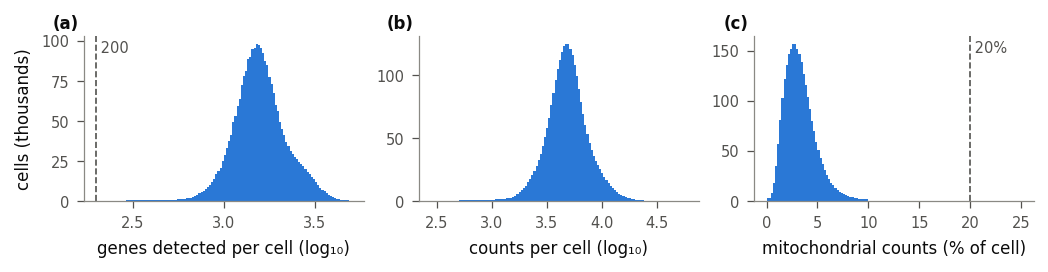

**Per-cell quality-control metrics of the subsampled single cells.** Histograms over all 2,586,999 cells in the 868 single-cell samples (up to 3,000 cells per sample): (a) genes detected per cell and (b) counts per cell, both on a log₁₀ scale, and (c) the percentage of a cell's counts from the 13 mitochondrial genes. Dashed lines mark the quality-control thresholds: at least 200 genes detected and less than 20% mitochondrial counts. Every cell passes both thresholds, consistent with the provider's files already being filtered, so quality control removes no cells and leaves the composition unchanged.

In [7]:
# Figure 0.1: per-cell QC metrics of all subsampled cells, with the thresholds.
fig, ax = figure("double", 1.7, 1, 3)
ax[0].hist(np.log10(cell_qc["genes_detected"].clip(lower=1)), bins=120, color=SERIES[0])
ax[0].axvline(np.log10(MIN_GENES), **THRESHOLD)
ax[0].text(np.log10(MIN_GENES), ax[0].get_ylim()[1] * .9, f" {MIN_GENES}", color=INK_2, fontsize=7)
ax[0].set(xlabel="genes detected per cell (log₁₀)")
ax[1].hist(np.log10(cell_qc["total_counts"].clip(lower=1)), bins=120, color=SERIES[0])
ax[1].set(xlabel="counts per cell (log₁₀)")
ax[2].hist(cell_qc["pct_mito"], bins=120, range=(0, 25), color=SERIES[0])
ax[2].axvline(MAX_PCT_MITO, **THRESHOLD)
ax[2].text(MAX_PCT_MITO, ax[2].get_ylim()[1] * .9, f" {MAX_PCT_MITO:g}%", color=INK_2, fontsize=7)
ax[2].set(xlabel="mitochondrial counts (% of cell)")
ax[0].set_ylabel("cells (thousands)")
for a in ax:
    a.yaxis.set_major_formatter(lambda v, _: f"{v / 1e3:g}")
panel_labels(ax)
save_show(fig, FIG, "0.1_cell_qc")
show_caption("0.1_cell_qc")

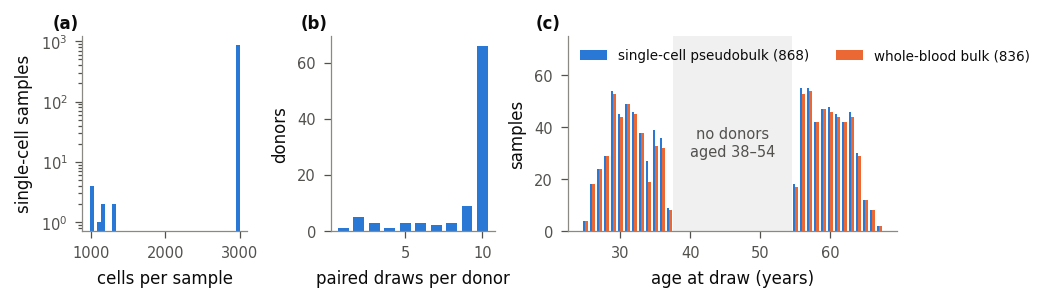

**Samples and donors of the Sound Life cohort.** (a) Cells per single-cell sample in the subsample (log-scale count of samples). All but 9 of the 868 samples contribute 3,000 cells; the 9 smaller samples contribute every cell they have (minimum 984). (b) Number of paired draws per donor for the 96 donors (median 10, range 1–10). (c) Samples by age at draw, for the 868 single-cell pseudobulk samples and the 836 whole-blood bulk samples. The cohort has two age groups, young (25–37 years) and older (55–67 years), with no donors aged 38–54 (shaded).

In [8]:
# Figure 0.2: samples and donors. (a) subsampled cells per sample, (b) draws per donor, (c) samples by age on each side.
o = sc_pb.obs
fig, ax = figure("double", 1.9, 1, 3, gridspec_kw={"width_ratios": [1, 1, 2]})
ax[0].hist(o["n_cells_slim"], bins=40, color=SERIES[0])
ax[0].set(xlabel="cells per sample", ylabel="single-cell samples", yscale="log")
draws = bulk.obs["donor_id"].value_counts()
ax[1].bar(*np.unique(draws, return_counts=True), color=SERIES[0], width=0.7)
ax[1].set(xlabel="paired draws per donor", ylabel="donors")
ages_sc = sc_pb.obs["numeric"].astype(float).round().astype(int).value_counts()
ages_b = bulk.obs["numeric"].astype(float).round().astype(int).value_counts()
grid = np.arange(min(ages_sc.index.min(), ages_b.index.min()), max(ages_sc.index.max(), ages_b.index.max()) + 1)
ax[2].bar(grid - 0.2, ages_sc.reindex(grid, fill_value=0), width=0.4, color=DOMAIN["single-cell"], label=f"{LABELS['sc']} ({len(o)})")
ax[2].bar(grid + 0.2, ages_b.reindex(grid, fill_value=0), width=0.4, color=DOMAIN["bulk"], label=f"{LABELS['bulk']} ({len(bulk)})")
ax[2].axvspan(37.5, 54.5, color=MUTED, alpha=0.12, lw=0)
ax[2].text(46, ax[2].get_ylim()[1] * 0.5, "no donors\naged 38–54", ha="center", color=INK_2, fontsize=7)
ax[2].set(xlabel="age at draw (years)", ylabel="samples", ylim=(0, ax[2].get_ylim()[1] * 1.3))
ax[2].legend(loc="upper left", ncol=2, fontsize=6.5)
panel_labels(ax)
save_show(fig, FIG, "0.2_samples_donors")
show_caption("0.2_samples_donors")

**Diagnostic (not in report).** A cell-level UMAP of a seeded sample of 60 passing cells per sample (about 52,000 cells), colored by AIFI_L1 class and by age group. It checks that the provider's labels form coherent groups in our counts.

<env>/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.10/site-pac

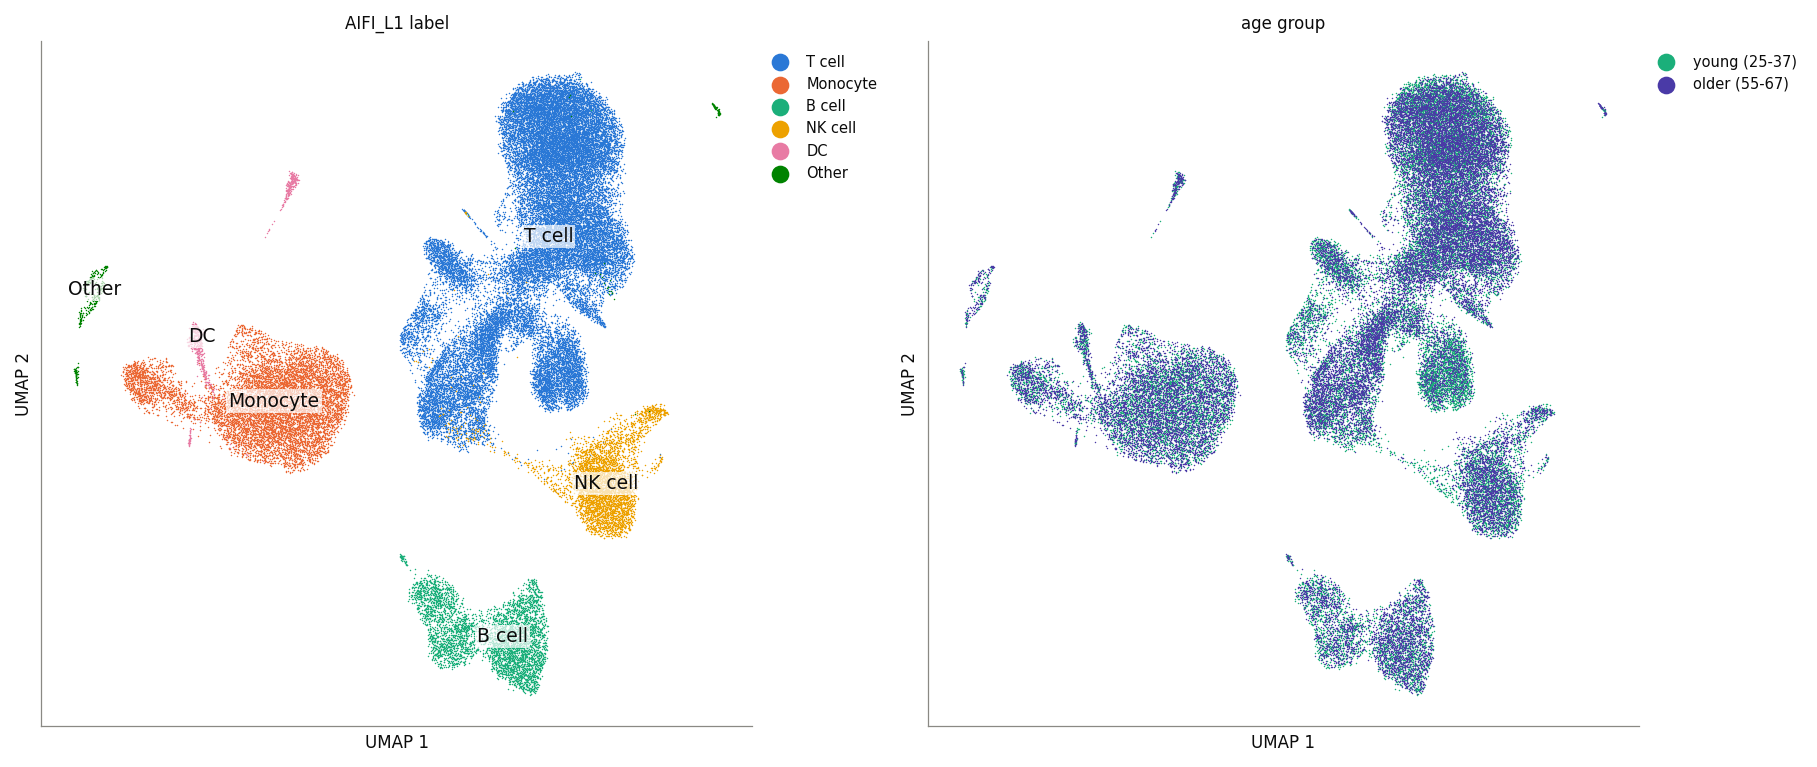

In [9]:
# Diagnostic (not in report): cell-level UMAP on the 60-cells-per-sample sample (~52k cells), by AIFI_L1 and by age group.
# Checks that the provider's labels form coherent groups in our counts. UMAP is cached with the cell sample.
import scanpy as sc
cells = ad.read_h5ad(cells_path)
# Keyed on this cell's code too, so changing the UMAP recipe recomputes the embedding.
UMAP_PARAMS = json.dumps({"code": this_cell_sha("UMAP_PARAMS ="), "n_top_genes": 2000, "n_pcs": 30, "n_neighbors": 15, "seed": 0}, sort_keys=True)
if "X_umap" not in cells.obsm or cells.uns.get("umap_params") != UMAP_PARAMS:
    work = cells.copy()
    sc.pp.normalize_total(work, target_sum=TARGET_SUM); sc.pp.log1p(work)
    sc.pp.highly_variable_genes(work, n_top_genes=2000, flavor="seurat")
    work = work[:, work.var["highly_variable"]].copy()
    sc.pp.scale(work, max_value=10); sc.tl.pca(work, n_comps=30, random_state=0)
    sc.pp.neighbors(work, n_neighbors=15, random_state=0); sc.tl.umap(work, random_state=0)
    cells.obsm["X_umap"] = work.obsm["X_umap"]
    cells.uns["umap_params"] = UMAP_PARAMS
    cells.write_h5ad(cells_path)
xy = cells.obsm["X_umap"]
show = ["T cell", "Monocyte", "B cell", "NK cell", "DC"]   # the rest is "Other"
order = np.random.default_rng(0).permutation(len(cells))      # random draw order, so no group sits on top
l1 = cells.obs["AIFI_L1"].astype(str).where(cells.obs["AIFI_L1"].isin(show), "Other").to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for k, c in enumerate(show + ["Other"]):
    m = l1[order] == c
    ax[0].scatter(*xy[order][m].T, s=0.5, color=SERIES[k], rasterized=True, linewidths=0, label=c)
    cx, cy = np.median(xy[l1 == c], axis=0)
    ax[0].text(cx, cy, c, ha="center", va="center", color=INK, fontsize=9, bbox=dict(fc="white", ec="none", alpha=0.7, pad=1))
ax[0].legend(markerscale=12, loc="upper left", bbox_to_anchor=(1, 1))
grp = np.where(cells.obs["numeric"].astype(float).to_numpy() >= 55, "older (55-67)", "young (25-37)")
for label in AGE:
    m = grp[order] == label
    ax[1].scatter(*xy[order][m].T, s=0.5, color=AGE[label], rasterized=True, linewidths=0, label=label)
ax[1].legend(markerscale=12, loc="upper left", bbox_to_anchor=(1, 1))
for a, t in zip(ax, ["AIFI_L1 label", "age group"]):
    a.set(xticks=[], yticks=[], xlabel="UMAP 1", ylabel="UMAP 2", title=t); a.grid(False)
plt.show()   # diagnostic only, not saved to results/

In [10]:
# Bulk library QC.
bo = bulk.obs
print(f"bulk kits: {len(bo)}; library size median {bo['library_size'].median():,.0f} (min {bo['library_size'].min():,.0f}); "
      f"genes detected median {bo['genes_detected'].median():,.0f}")
print(f"mito frac median {bo['mito_frac'].median():.3f} (max {bo['mito_frac'].max():.3f}); "
      f"globin frac median {bo['globin_frac'].median():.3f} (max {bo['globin_frac'].max():.3f})")
assert bo["globin_frac"].max() < 0.05, "globin dominates some bulk libraries; reconsider normalization"

bulk kits: 836; library size median 3,466,414 (min 1,220,532); genes detected median 17,451
mito frac median 0.018 (max 0.036); globin frac median 0.005 (max 0.021)


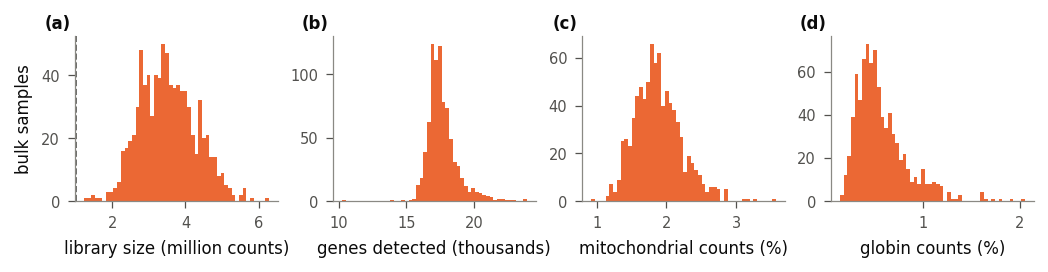

**Library quality of the 836 whole-blood bulk samples.** (a) Library size, (b) genes detected, (c) percentage of counts from mitochondrial genes and (d) percentage of counts from hemoglobin (globin) genes, per sample kit; the 2 kits sequenced twice are shown with their libraries summed. The dashed line in (a) marks the 1-million-count threshold; every library lies above it (minimum 1,220,532 counts). The globin fraction is at most 2.1%, so globin transcripts do not dominate any library.

In [11]:
# Figure 0.5: bulk library QC.
fig, ax = figure("double", 1.7, 1, 4)
ax[0].hist(bo["library_size"] / 1e6, bins=50, color=DOMAIN["bulk"]); ax[0].axvline(BULK_MIN_LIBRARY / 1e6, **THRESHOLD)
ax[0].set(xlabel="library size (million counts)", ylabel="bulk samples")
ax[1].hist(bo["genes_detected"] / 1e3, bins=50, color=DOMAIN["bulk"]); ax[1].set(xlabel="genes detected (thousands)")
ax[2].hist(100 * bo["mito_frac"], bins=50, color=DOMAIN["bulk"]); ax[2].set(xlabel="mitochondrial counts (%)")
ax[3].hist(100 * bo["globin_frac"], bins=50, color=DOMAIN["bulk"]); ax[3].set(xlabel="globin counts (%)")
panel_labels(ax)
save_show(fig, FIG, "0.5_bulk_qc")
show_caption("0.5_bulk_qc")

All 2,586,999 subsampled cells passed (0.00% had fewer than 200 genes and 0.00% had 20% or more mitochondrial counts), so the composition before and after quality control is identical (table above). This is consistent with the provider's files already being filtered at these or stricter thresholds; here quality control acts as a guard rather than a filter (figure 0.1). The 868 single-cell samples hold a median of 3,000 cells (minimum 984); 9 samples had fewer than 3,000 cells in total and contribute every cell (figure 0.2). On the bulk side, 2 of the 836 kits had two libraries, which were summed, and none fell below 1 million counts. The median library size is 3,466,414 counts (minimum 1,220,532), with a median of 17,451 genes detected, a median mitochondrial fraction of 1.8% (maximum 3.6%) and a median globin fraction of 0.5% (maximum 2.1%) (figure 0.5).

### 4.2 Pairs and composition

**All 836 bulk kits pair with a single-cell sample from the same draw, and the metadata of every pair agree.**

In [12]:
sc_ok = sc_pb.obs.index[sc_pb.obs["n_cells_pass"] >= MIN_CELLS_PER_SAMPLE]
bulk_ok = bulk.obs.index[bulk.obs["passed_qc"]]
PAIRS = pd.Index(sorted(set(sc_ok) & set(bulk_ok)))
# Expected counts: 868 single-cell samples, 836 bulk kits, 96 donors on both sides
assert len(sc_ok) == 868 and len(bulk_ok) == 836 and len(PAIRS) == 836
assert set(sc_pb.obs["donor_id"]) == set(bulk.obs["donor_id"]) and bulk.obs["donor_id"].nunique() == 96, "donors differ between sides"
print(f"single-cell samples {len(sc_pb)} ({len(sc_ok)} pass), bulk kits {len(bulk)} ({len(bulk_ok)} pass) -> {len(PAIRS)} pairs")
print(f"single-cell only: {len(set(sc_pb.obs.index) - set(bulk.obs.index))}; bulk only: {len(set(bulk.obs.index) - set(sc_pb.obs.index))}")

s, b = sc_pb.obs.loc[PAIRS], bulk.obs.loc[PAIRS]
assert (s["donor_id"] == b["donor_id"]).all(), "a pair's donor differs between sides"
assert np.allclose(s["numeric"].astype(float), b["numeric"].astype(float)), "a pair's age differs between sides"
for c in ("sex", "cmv", "timepoint"):
    bad = s[c].str.lower() != b[c].str.lower()
    assert not bad.any(), f"{c}: {bad.sum()} pairs disagree, e.g. {s.loc[bad, c].iloc[0]!r} vs {b.loc[bad, c].iloc[0]!r}"
print("sex, cmv, timepoint agree for every pair")

age = b["numeric"].astype(float)
assert not ((age > 37) & (age < 55)).any(), "an age falls in the 38-54 gap"
AGE_GROUP = (age >= 55).astype(int)       # 0 young (25-37), 1 older (55-67)
# ...and it must match the provider's own label on both sides
assert ((b["age_group"] == "Older Adult") == (AGE_GROUP == 1)).all() and ((s["age_group"] == "Sound Life Older Adult") == (AGE_GROUP == 1)).all()
DONORS = b["donor_id"].astype(str)
assert (AGE_GROUP.groupby(DONORS, observed=True).nunique() == 1).all(), "a donor's age group changes across draws"
print(f"{DONORS.nunique()} donors ({AGE_GROUP.groupby(DONORS, observed=True).first().value_counts().to_dict()} young/older), "
      f"{DONORS.value_counts().median():.0f} draws per donor (range {DONORS.value_counts().min()}-{DONORS.value_counts().max()})")

single-cell samples 868 (868 pass), bulk kits 836 (836 pass) -> 836 pairs
single-cell only: 32; bulk only: 0
sex, cmv, timepoint agree for every pair
96 donors ({0: 49, 1: 47} young/older), 10 draws per donor (range 1-10)


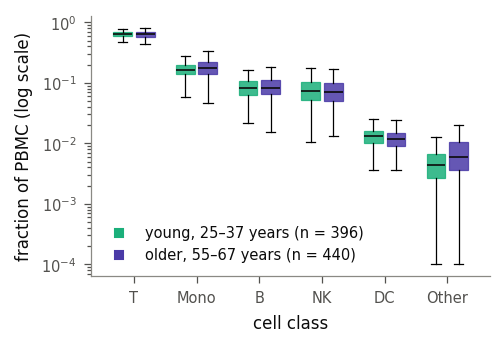

**Measured PBMC composition of the 836 paired samples, by donor age group.** Box plots of the fraction of peripheral blood mononuclear cells (PBMC) in each of the six target classes: T cells (T), monocytes (Mono), B cells (B), natural killer cells (NK), dendritic cells (DC) and Other, which pools platelets, erythrocytes, progenitor cells and innate lymphoid cells. Fractions are computed from all cells of each single-cell sample that pass quality control. Boxes span the interquartile range, the black line marks the median, and whiskers extend to 1.5 times the interquartile range; outliers are not drawn. The y axis is logarithmic, and samples with no cells in a class are drawn at 10⁻⁴. Sample counts per age group are in the legend. T cells make up most of PBMC in both age groups, and the composition differs little between them.

In [13]:
# Figure 0.3: composition c* of the 836 paired samples in the six target classes, young vs older donors.
comp9 = sc_pb.obs.loc[PAIRS, [f"frac_{c}" for c in L1_CLASSES]].set_axis(L1_CLASSES, axis=1)
show = ["T cell", "Monocyte", "B cell", "NK cell", "DC"]
comp6 = comp9[show].assign(Other=comp9.drop(columns=show).sum(axis=1))
older = sc_pb.obs.loc[PAIRS, "numeric"].astype(float) >= 55
fig, ax = figure("single", 2.2)
pos = np.arange(comp6.shape[1])
for group, mask, dx in [("young (25-37)", ~older, -0.18), ("older (55-67)", older, 0.18)]:
    bp = ax.boxplot([comp6.loc[mask, c].clip(lower=1e-4) for c in comp6.columns], positions=pos + dx, widths=0.3,
                    patch_artist=True, showfliers=False, medianprops=dict(color=INK, linewidth=0.8),
                    whiskerprops=dict(linewidth=0.6), capprops=dict(linewidth=0.6))
    for box in bp["boxes"]:
        box.set(facecolor=AGE[group], alpha=0.85, edgecolor=AGE[group], linewidth=0.6)
    ax.plot([], [], "s", color=AGE[group], label=f"{group.split(' (')[0]}, {group.split('(')[1].rstrip(')').replace('-', '–')} years (n = {mask.sum()})")
ax.set_xticks(pos, [LABELS.get(c, c) for c in comp6.columns]); ax.set_yscale("log")
ax.set(xlabel="cell class", ylabel="fraction of PBMC (log scale)")
ax.legend(loc="lower left")
save_show(fig, FIG, "0.3_composition")
show_caption("0.3_composition")

The 836 pairs come from 96 donors (49 young, 47 older), with a median of 10 draws per donor (range 1–10). T cells dominate PBMC composition. The mean fractions over the 836 pairs (printed when the pairs file is written, §4.4) are 63.5% T, 17.8% Mono, 8.7% B, 8.1% NK, 1.3% DC and 0.7% Other (figure 0.3). The four classes pooled into Other each average under 0.5% of cells across the 868 single-cell samples (quality-control table in §4.1).

### 4.3 Donor split

**The donor split gives 582 / 135 / 119 pairs from 68 / 14 / 14 donors, with both age groups in every split.** The older group makes up 53.6% of training pairs, 48.1% of validation pairs and 52.9% of test pairs (last column of the table below).

In [14]:
def donor_split(donors, strata, fracs, seed):
    # {donor: split}: within each stratum (sorted), donors (sorted) are permuted with the seed and cut by fracs.
    table = pd.DataFrame({"donor": donors, "stratum": strata}).drop_duplicates("donor").sort_values("donor")
    rng = np.random.RandomState(seed)
    out = {}
    for _, g in table.groupby("stratum"):
        order = g["donor"].to_numpy()[rng.permutation(len(g))]
        n_test, n_val = round(fracs["test"] * len(order)), round(fracs["val"] * len(order))
        out.update({d: "test" for d in order[:n_test]})
        out.update({d: "val" for d in order[n_test:n_test + n_val]})
        out.update({d: "train" for d in order[n_test + n_val:]})
    return out

split_of = donor_split(DONORS.to_numpy(), AGE_GROUP.to_numpy(), SPLIT_FRACS, SPLIT_SEED)
SPLIT = DONORS.map(split_of)
donor_sets = {k: set(DONORS[SPLIT == k]) for k in SPLIT_FRACS}
assert not (donor_sets["train"] & donor_sets["val"] or donor_sets["train"] & donor_sets["test"] or donor_sets["val"] & donor_sets["test"])
for k in ("val", "test"):
    assert set(AGE_GROUP[SPLIT == k]) == {0, 1}, f"{k} lacks an age group"
summary = pd.DataFrame({k: {"donors": len(donor_sets[k]), "pairs": (SPLIT == k).sum(),
                            "older_frac": AGE_GROUP[SPLIT == k].mean()} for k in SPLIT_FRACS}).T
display(summary)


,donors,pairs,older_frac
train,68.0,582.0,0.536082
val,14.0,135.0,0.481481
test,14.0,119.0,0.529412


**Diagnostic (not in report).** Donors and pairs per split, by age group.

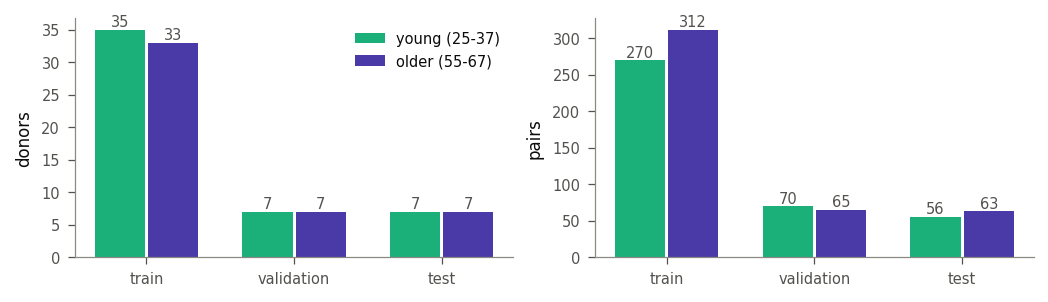

In [15]:
# Donors and pairs per split, by age group (diagnostic, not saved).
tab = pd.DataFrame({"split": SPLIT, "age": np.where(AGE_GROUP == 1, "older (55-67)", "young (25-37)"), "donor": DONORS})
donors_tab = tab.drop_duplicates("donor").groupby(["split", "age"]).size().unstack().reindex(list(SPLIT_FRACS))
pairs_tab = tab.groupby(["split", "age"]).size().unstack().reindex(list(SPLIT_FRACS))
fig, ax = figure("double", 1.9, 1, 2)
for a, t, what in [(ax[0], donors_tab, "donors"), (ax[1], pairs_tab, "pairs")]:
    x = np.arange(len(t))
    for k, group in enumerate(AGE):
        bars = a.bar(x + (k - 0.5) * 0.36, t[group], width=0.34, color=AGE[group], label=group)
        a.bar_label(bars, color=INK_2, fontsize=7)
    a.set_xticks(x, ["train", "validation", "test"]); a.set_ylabel(what)
ax[0].legend(loc="upper right")
plt.show()

### 4.4 Shared genes, normalization and gene panel

**The 5,000-gene panel is chosen from 13,775 genes detected in both domains, using training donors only, and it does not depend on held-out donors.** The next cell normalizes both domains, selects the panel and runs the leakage check; the cell after it writes the model-ready pairs file.

In [16]:
SHARED = SC_GENES.intersection(bulk.var_names)
print(f"genes: single-cell {len(SC_GENES):,}, bulk {bulk.n_vars:,}, shared {len(SHARED):,}")

def log_cp10k(counts):
    counts = np.asarray(counts, dtype=np.float64)
    lib = counts.sum(axis=1, keepdims=True)
    return np.log1p(counts / lib * TARGET_SUM).astype(np.float32)

counts_sc = sc_pb[PAIRS, SHARED].X.toarray()
counts_bulk = bulk[PAIRS, SHARED].X.toarray()
L_sc, L_bulk = log_cp10k(counts_sc), log_cp10k(counts_bulk)     # library over all shared genes

# Check: our normalization equals scanpy's normalize_total + log1p.
import scanpy as sc
_check = ad.AnnData(counts_sc[:50].astype(np.float32))
sc.pp.normalize_total(_check, target_sum=TARGET_SUM); sc.pp.log1p(_check)
assert np.allclose(_check.X, L_sc[:50], atol=1e-5)

def dispersion_rank(logx, genes):
    # scanpy's highly_variable_genes(flavor="seurat") normalized dispersion; rank 1 = most variable,
    # ties broken by gene symbol so the panel is deterministic.
    a = ad.AnnData(logx.astype(np.float32), var=pd.DataFrame(index=genes))
    sc.pp.highly_variable_genes(a, flavor="seurat", n_bins=20, inplace=True)
    t = a.var[["dispersions_norm"]].assign(gene=genes).sort_values(["dispersions_norm", "gene"], ascending=[False, True], na_position="last")
    return pd.Series(np.arange(1, len(t) + 1), index=t.index).reindex(genes).to_numpy()

def make_panel(cs, cb, train):
    detected = ((cs[train] > 0).mean(0) >= PANEL_MIN_DETECTED) & ((cb[train] > 0).mean(0) >= PANEL_MIN_DETECTED)
    cand = np.flatnonzero(detected)
    genes = SHARED[cand]
    rank = (dispersion_rank(log_cp10k(cs[train])[:, cand], genes) + dispersion_rank(log_cp10k(cb[train])[:, cand], genes)) / 2
    order = pd.DataFrame({"rank": rank, "gene": genes}).sort_values(["rank", "gene"]).index
    return genes[order[:PANEL_SIZE]], len(cand)

train = (SPLIT == "train").to_numpy()
PANEL, n_cand = make_panel(counts_sc, counts_bulk, train)
panel_idx = SHARED.get_indexer(PANEL)
print(f"{n_cand:,} genes detected in >= {PANEL_MIN_DETECTED:.0%} of training samples on both sides -> panel of {len(PANEL)}")
must_have = ["CD3E", "CD14", "MS4A1", "NKG7", "FCGR3B", "CSF3R", "S100A8", "HBB"]
print("marker genes in panel:", {g: g in PANEL for g in must_have})

# Leak check: the panel must not depend on validation or test donors. Permute their genes and
# rebuild; the panel must come out identical.
rng = np.random.default_rng(0)
held = np.flatnonzero(~train)
perm_sc, perm_bulk = counts_sc.copy(), counts_bulk.copy()
perm_sc[held] = perm_sc[held][:, rng.permutation(perm_sc.shape[1])]
perm_bulk[held] = perm_bulk[held][:, rng.permutation(perm_bulk.shape[1])]
assert make_panel(perm_sc, perm_bulk, train)[0].equals(PANEL), "the panel depends on val/test donors"
print("panel is unchanged when val/test donors' data are scrambled")

genes: single-cell 33,514, bulk 58,302, shared 32,965


<env>/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]


<env>/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]


13,775 genes detected in >= 50% of training samples on both sides -> panel of 5000
marker genes in panel: {'CD3E': False, 'CD14': True, 'MS4A1': True, 'NKG7': True, 'FCGR3B': True, 'CSF3R': True, 'S100A8': True, 'HBB': True}


<env>/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]


panel is unchanged when val/test donors' data are scrambled


<env>/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]


In [17]:
x_sc, x_bulk = L_sc[:, panel_idx], L_bulk[:, panel_idx]
# Task-net targets: the five main lineages, plus "Other" for the four tiny classes (Platelet,
# Erythrocyte, Progenitor cell, ILC; each <0.5% of cells). Full 9-class fractions stay in sc_pseudobulk_counts.h5ad.
COMP_CLASSES = ["T cell", "Monocyte", "B cell", "NK cell", "DC"]
fracs = sc_pb.obs.loc[PAIRS, [f"frac_{c}" for c in L1_CLASSES]].set_axis(L1_CLASSES, axis=1)
fracs["Other"] = fracs.drop(columns=COMP_CLASSES).sum(axis=1)
COMP_CLASSES.append("Other")
composition = fracs[COMP_CLASSES].to_numpy(np.float32)
save_pairs(   # checks the schema (shapes, dtypes, finite, simplex, donor-disjoint splits)
    paths.PAIRS_FILE, x_sc=x_sc, x_bulk=x_bulk, composition=composition, l1_classes=COMP_CLASSES, genes=PANEL,
    sample_ids=PAIRS, donor_ids=DONORS.to_numpy(), age=age.to_numpy(np.float32),
    age_group=AGE_GROUP.to_numpy(), split=SPLIT.to_numpy(),
)
pairs = load_pairs()   # and reads it back the way every later phase will
print(f"saved {paths.PAIRS_FILE}: x_sc/x_bulk {x_sc.shape}, composition {composition.shape}")
print("composition classes (mean fraction):", dict(zip(COMP_CLASSES, composition.mean(0).round(4))))
print(f"mean log-CP10k on panel: single-cell {x_sc.mean():.3f}, bulk {x_bulk.mean():.3f}")

saved <repo>/data/processed/soundlife_pairs.npz: x_sc/x_bulk (836, 5000), composition (836, 6)
composition classes (mean fraction): {'T cell': 0.6347, 'Monocyte': 0.1778, 'B cell': 0.0871, 'NK cell': 0.0808, 'DC': 0.0128, 'Other': 0.0068}
mean log-CP10k on panel: single-cell 0.265, bulk 0.421


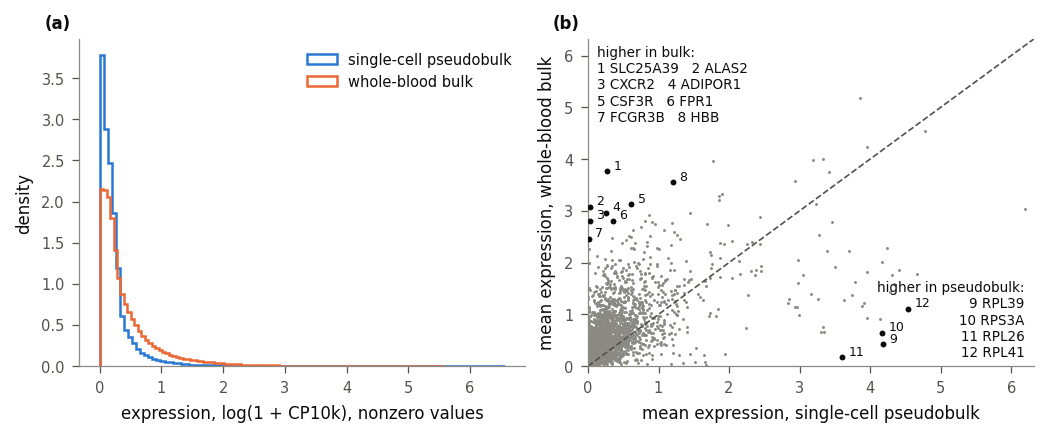

**Expression of the 5,000 panel genes in the two domains.** (a) Distribution of nonzero log(1 + CP10k) values (counts per 10,000, log-transformed) in single-cell pseudobulk and whole-blood bulk, over the 836 paired samples. (b) Mean expression of each panel gene in pseudobulk (x) against bulk (y); the dashed line is equality. The eight genes with the largest excess in bulk and the four with the largest excess in pseudobulk are numbered and named in the key. Genes far above the line are granulocyte genes (for example CXCR2, CSF3R, FCGR3B) and erythroid genes (ALAS2, HBB), which whole blood contains and PBMC lacks; genes below it are ribosomal protein genes.

In [18]:
# Figure 0.7: expression on the panel. (a) distribution of nonzero values per domain;
# (b) per-gene mean, pseudobulk vs bulk: genes far above the diagonal are bulk-only (granulocyte, globin).
fig, ax = figure("double", 2.8, 1, 2)
for name, key, x in [("single-cell", "sc", x_sc), ("bulk", "bulk", x_bulk)]:
    v = x[x > 0]
    ax[0].hist(v, bins=100, density=True, histtype="step", linewidth=1.2, color=DOMAIN[name], label=LABELS[key])
ax[0].set(xlabel="expression, log(1 + CP10k), nonzero values", ylabel="density"); ax[0].legend()
m_sc, m_b = x_sc.mean(0), x_bulk.mean(0)
ax[1].scatter(m_sc, m_b, s=2, color=MUTED, rasterized=True, linewidths=0)
lim = [0, max(m_sc.max(), m_b.max()) * 1.02]
ax[1].plot(lim, lim, **THRESHOLD)
diff = pd.Series(m_b - m_sc, index=PANEL)
# Number the largest gaps each way on the plot, with a key beside it (names on the points collide).
k = 0
for side, genes_lab, (tx, ty, ha, va) in [("higher in bulk", diff.nlargest(8).index, (0.02, 0.98, "left", "top")),
                                          ("higher in pseudobulk", diff.nsmallest(4).index, (0.98, 0.02, "right", "bottom"))]:
    key = []
    for g in genes_lab:
        k += 1; j = PANEL.get_loc(g)
        ax[1].scatter(m_sc[j], m_b[j], s=8, color=INK, zorder=3, linewidths=0)
        ax[1].annotate(str(k), (m_sc[j], m_b[j]), xytext=(3, 1), textcoords="offset points", fontsize=6, color=INK)
        key.append(f"{k} {g}")
    rows = [key[i:i + 2] for i in range(0, len(key), 2)] if len(key) > 4 else [[x] for x in key]
    ax[1].text(tx, ty, f"{side}:\n" + "\n".join("   ".join(r) for r in rows), transform=ax[1].transAxes, ha=ha, va=va, fontsize=6.5, color=INK)
ax[1].set(xlabel="mean expression, single-cell pseudobulk", ylabel="mean expression, whole-blood bulk", xlim=lim, ylim=lim)
panel_labels(ax)
save_show(fig, FIG, "0.7_expression")
show_caption("0.7_expression")

<env>/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
<env>/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]


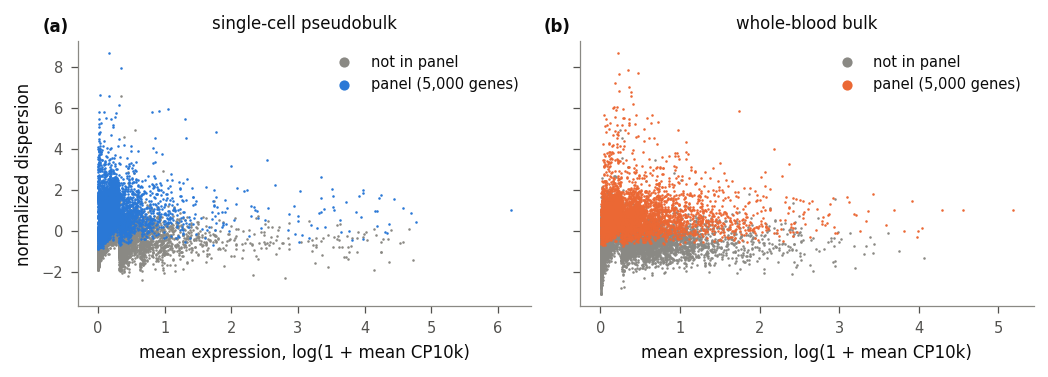

**Selection of the 5,000-gene panel on the training donors.** Normalized dispersion against mean expression for the 13,775 genes detected in at least 50% of training samples in both domains, computed separately on the 582 training samples of (a) single-cell pseudobulk and (b) whole-blood bulk. Dispersion is the variance-to-mean ratio of a gene, normalized within bins of mean expression (the Seurat flavor of highly variable gene selection in scanpy). Each gene is ranked by normalized dispersion within each domain, the two ranks are averaged, and the 5,000 best genes form the panel (colored); the other candidates are gray. No validation or test donor is used.

In [19]:
# Figure 0.8: panel selection on the training donors. Normalized dispersion vs mean per domain
# (scanpy seurat flavor) for the candidate genes; the 5,000 panel genes are highlighted.
import scanpy as sc
cand = np.flatnonzero(((counts_sc[train] > 0).mean(0) >= PANEL_MIN_DETECTED) & ((counts_bulk[train] > 0).mean(0) >= PANEL_MIN_DETECTED))
in_panel = np.isin(SHARED[cand], PANEL)
fig, ax = figure("double", 2.4, 1, 2, sharey=True)
for a, (name, key, L) in zip(ax, [("single-cell", "sc", L_sc), ("bulk", "bulk", L_bulk)]):
    t = ad.AnnData(L[train][:, cand].astype(np.float32), var=pd.DataFrame(index=SHARED[cand]))
    sc.pp.highly_variable_genes(t, flavor="seurat", n_bins=20)
    v = t.var
    a.scatter(v["means"][~in_panel], v["dispersions_norm"][~in_panel], s=1.5, color=MUTED, rasterized=True, linewidths=0, label="not in panel")
    a.scatter(v["means"][in_panel], v["dispersions_norm"][in_panel], s=1.5, color=DOMAIN[name], rasterized=True, linewidths=0,
              label=f"panel ({in_panel.sum():,} genes)")
    a.set(xlabel="mean expression, log(1 + mean CP10k)", title=LABELS[key])
    a.legend(markerscale=4, loc="upper right")
ax[0].set_ylabel("normalized dispersion")
panel_labels(ax)
save_show(fig, FIG, "0.8_panel")
show_caption("0.8_panel")

The single-cell and bulk annotations share 32,965 of 33,514 and 58,302 genes. Of these, 13,775 are detected in at least 50% of training samples in both domains, and the panel keeps 5,000 of them (figure 0.8). The panel is identical when the validation and test donors' expression values are permuted, so it carries no held-out information. The canonical T-cell markers CD3E, CD3D and TRAC are not in the panel, while the monocyte (CD14), B-cell (MS4A1), NK (NKG7), myeloid (S100A8), granulocyte (FCGR3B, CSF3R) and globin (HBB) markers are. On the panel, the mean expression is 0.265 in single-cell pseudobulk and 0.421 in whole-blood bulk, in log(1 + CP10k) units. Among the genes with the largest mean difference, those higher in bulk include granulocyte genes (CXCR2, CSF3R, FPR1, FCGR3B) and erythroid genes (ALAS2, HBB), and those higher in pseudobulk are ribosomal protein genes (labeled in figure 0.7b).

### 4.5 Marker–composition agreement

**Marker genes track the measured composition in both domains, more weakly in whole blood.** The first table below gives Spearman's ρ between each marker and its lineage's fraction across the 836 pairs, in each domain; the second gives the granulocyte genes' mean expression (§4.6).

In [20]:
# NKG7/GNLY are shared with cytotoxic CD8 T cells, so they track NK fraction only loosely;
# KLRF1/SH2D1B/NCAM1 are NK-specific. The check uses the best marker per lineage.
markers = {"T cell": ["CD3E", "CD3D", "TRAC"], "B cell": ["MS4A1", "CD79A", "CD19"], "Monocyte": ["CD14", "LYZ", "FCN1"],
           "NK cell": ["KLRF1", "SH2D1B", "NCAM1", "NKG7", "GNLY"], "DC": ["FCER1A", "CLEC10A", "LILRA4"]}
rows = []
for cell_type, genes in markers.items():
    frac = sc_pb.obs.loc[PAIRS, f"frac_{cell_type}"].to_numpy()
    for g in genes:
        if g not in SHARED:
            continue
        j = SHARED.get_loc(g)
        rows.append({"cell_type": cell_type, "gene": g, "in_panel": g in PANEL,
                     "rho_single_cell": spearmanr(L_sc[:, j], frac)[0], "rho_bulk": spearmanr(L_bulk[:, j], frac)[0]})
marker_check = pd.DataFrame(rows)
display(marker_check.style.format({"rho_single_cell": "{:.2f}", "rho_bulk": "{:.2f}"}))
best = marker_check.groupby("cell_type")[["rho_single_cell", "rho_bulk"]].max()
assert (best.loc[["T cell", "B cell", "Monocyte", "NK cell"], "rho_single_cell"] > 0.5).all(), "a lineage's markers don't track its fraction"

gran = [g for g in ["FCGR3B", "CSF3R", "CXCR2", "CXCR1", "FPR1", "CMTM2", "MME"] if g in SHARED]
gran_tab = pd.DataFrame({g: {"single_cell": L_sc[:, SHARED.get_loc(g)].mean(), "bulk": L_bulk[:, SHARED.get_loc(g)].mean()}
                         for g in gran}).T
gran_tab["bulk_minus_sc"] = gran_tab["bulk"] - gran_tab["single_cell"]
display(gran_tab.style.format("{:.2f}"))
# CMTM2/MME are lower-expressed, so their gap is smaller; require a clear median gap and no reversals.
assert gran_tab["bulk_minus_sc"].median() > 1 and (gran_tab["bulk_minus_sc"] > 0).all(), "granulocyte genes aren't clearly higher in whole blood"

,cell_type,gene,in_panel,rho_single_cell,rho_bulk
0,T cell,CD3E,False,0.72,0.51
1,T cell,CD3D,False,0.76,0.51
2,T cell,TRAC,False,0.58,0.51
3,B cell,MS4A1,True,0.89,0.57
4,B cell,CD79A,True,0.85,0.75
5,B cell,CD19,True,0.84,0.68
6,Monocyte,CD14,True,0.81,0.58
7,Monocyte,LYZ,True,0.72,0.12
8,Monocyte,FCN1,True,0.81,0.56
9,NK cell,KLRF1,True,0.79,0.60


,single_cell,bulk,bulk_minus_sc
FCGR3B,0.01,2.46,2.45
CSF3R,0.62,3.13,2.51
CXCR2,0.03,2.81,2.77
CXCR1,0.01,2.27,2.26
FPR1,0.35,2.81,2.46
CMTM2,0.03,0.97,0.95
MME,0.01,0.60,0.59


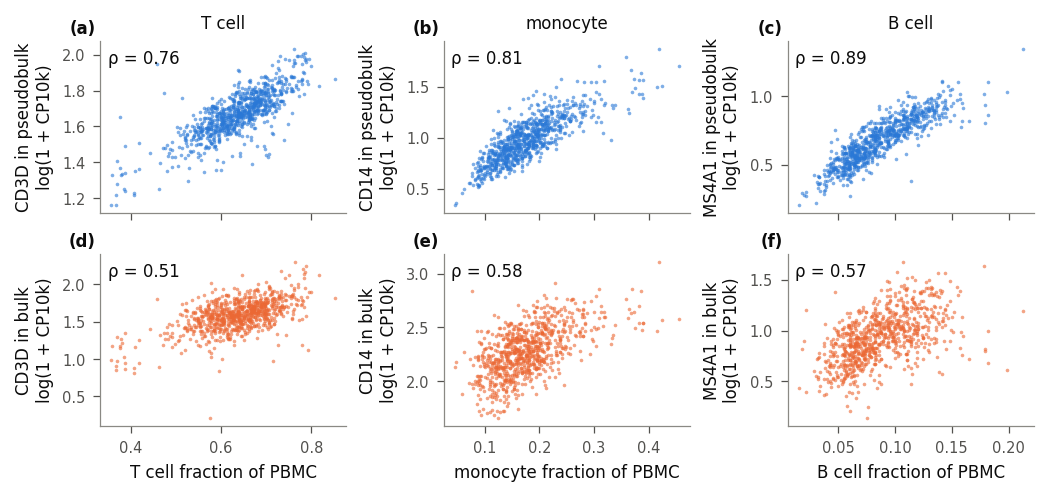

**Marker expression tracks measured composition in both domains.** For T cells, monocytes and B cells, the marker gene with the highest Spearman rank correlation (ρ) with its lineage's fraction in single-cell pseudobulk (named on the y axis), plotted against that measured fraction for the 836 paired samples from 96 donors. (a–c) Expression in single-cell pseudobulk; (d–f) expression of the same gene in whole-blood bulk from the same draws. Expression is log(1 + CP10k); fractions are of PBMC. Each panel gives Spearman's ρ across the 836 pairs. Agreement is strong in pseudobulk and weaker but clear in whole blood, so the PBMC composition can be read from a bulk profile; the NK and dendritic-cell markers follow the same pattern.

In [21]:
# Figure 0.9: the best marker per lineage (highest single-cell ρ) vs that lineage's measured fraction, both domains.
# The three most abundant lineages are shown; NK and DC are in the marker table above.
best_gene = marker_check.loc[marker_check.groupby("cell_type")["rho_single_cell"].idxmax()].set_index("cell_type")["gene"]
lineages = ["T cell", "Monocyte", "B cell"]
fig, ax = figure("double", 3.2, 2, 3, sharex="col")
for col, ct in enumerate(lineages):
    g = best_gene[ct]; j = SHARED.get_loc(g)
    frac = sc_pb.obs.loc[PAIRS, f"frac_{ct}"].to_numpy()
    for row, (name, side, L) in enumerate([("single-cell", "pseudobulk", L_sc), ("bulk", "bulk", L_bulk)]):
        a = ax[row, col]
        a.scatter(frac, L[:, j], s=3, color=DOMAIN[name], alpha=0.6, linewidths=0, rasterized=True)
        rho = spearmanr(L[:, j], frac)[0]
        a.text(0.03, 0.95, f"ρ = {rho:.2f}", transform=a.transAxes, va="top", color=INK)
        a.set_ylabel(f"{g} in {side}\nlog(1 + CP10k)")
        if row == 0: a.set_title(ct.replace("Monocyte", "monocyte"))
        if row == 1: a.set_xlabel(f"{ct.replace('Monocyte', 'monocyte')} fraction of PBMC")
panel_labels(ax.ravel())
save_show(fig, FIG, "0.9_markers_vs_composition")
show_caption("0.9_markers_vs_composition")

Taking the best marker per lineage, ρ ranges from 0.75 to 0.89 in single-cell pseudobulk and from 0.45 to 0.75 in whole-blood bulk (table above; figure 0.9 for T cells, monocytes and B cells). In single-cell pseudobulk this confirms that the provider's labels agree with the counts. In bulk it shows that the PBMC-relative composition $c^*$ can be read from a whole-blood profile, though less precisely. Some markers transfer poorly to whole blood: the monocyte marker LYZ reaches ρ = 0.72 in pseudobulk but 0.12 in bulk, and the NK markers NKG7 and GNLY, which cytotoxic T cells also express, track NK fraction weakly in both domains (ρ 0.38–0.45 in pseudobulk). The NK-specific markers SH2D1B and KLRF1 do better (ρ 0.89 and 0.79 in pseudobulk, 0.70 and 0.60 in bulk).

### 4.6 Granulocyte genes

**Granulocyte genes are expressed in whole-blood bulk and nearly absent from PBMC pseudobulk.**

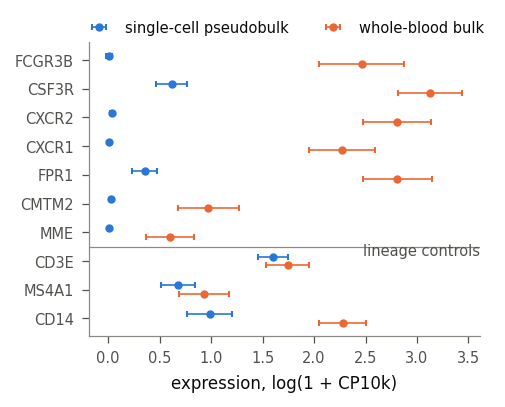

**Granulocyte genes are expressed in whole-blood bulk and nearly absent from PBMC pseudobulk.** Mean expression (dot) ± one standard deviation (bars) across the 836 paired samples, in log(1 + CP10k), for seven granulocyte genes (above the line) and three lineage markers as controls (below: CD3E for T cells, MS4A1 for B cells, CD14 for monocytes), in single-cell pseudobulk and whole-blood bulk. Five granulocyte genes are 2.26–2.77 units higher in bulk; the more weakly expressed CMTM2 and MME are 0.95 and 0.59 units higher. PBMC isolation removes granulocytes, so single-cell → bulk translation must generate this signal without any counterpart in its input.

In [22]:
# Figure 0.10: granulocyte genes (and lineage controls) by domain: mean ± SD across pairs.
genes_show = gran + ["CD3E", "MS4A1", "CD14"]
fig, ax = figure("single", 2.6)
y = np.arange(len(genes_show))
for k, (name, key, L) in enumerate([("single-cell", "sc", L_sc), ("bulk", "bulk", L_bulk)]):
    vals = np.array([L[:, SHARED.get_loc(g)] for g in genes_show])
    ax.errorbar(vals.mean(1), y + (k - 0.5) * 0.3, xerr=vals.std(1), fmt="o", ms=3, color=DOMAIN[name], label=LABELS[key], capsize=1.5, lw=0.8)
ax.axhline(len(gran) - 0.5, color=MUTED, lw=0.6)
ax.text(ax.get_xlim()[1], len(gran) - 0.6, "lineage controls", ha="right", va="top", color=INK_2, fontsize=7)
ax.set_yticks(y, genes_show); ax.invert_yaxis(); ax.set_xlabel("expression, log(1 + CP10k)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=2)
save_show(fig, FIG, "0.10_granulocyte_genes")
show_caption("0.10_granulocyte_genes")

Five granulocyte genes (FCGR3B, CSF3R, CXCR2, CXCR1, FPR1) are 2.26–2.77 log(1 + CP10k) units higher in bulk than in pseudobulk, and the more weakly expressed CMTM2 and MME are 0.95 and 0.59 units higher (second table in §4.5). Their mean pseudobulk expression is 0.01–0.62 units. PBMC isolation removes granulocytes, so this signal exists in only one domain (figure 0.10).

### 4.7 The domain gap

**The gap between the domains lies almost entirely on the first principal component, and pairing carries sample-level signal beyond it.** The table below gives, for the top five PCs of both domains together, the share of variance (first column) and η² for domain and for age group.

In [23]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

stack = np.vstack([x_sc, x_bulk])
domain = np.r_[np.zeros(len(x_sc)), np.ones(len(x_bulk))]
ages = np.r_[AGE_GROUP.to_numpy(), AGE_GROUP.to_numpy()]
pca = PCA(n_components=10, random_state=0)
pcs = pca.fit_transform(stack)

def eta2(v, g):
    grand = v.mean()
    return sum((g == l).sum() * (v[g == l].mean() - grand) ** 2 for l in np.unique(g)) / ((v - grand) ** 2).sum()

gap = pd.DataFrame({"var_ratio": pca.explained_variance_ratio_,
                    "eta2_domain": [eta2(pcs[:, i], domain) for i in range(10)],
                    "eta2_age": [eta2(pcs[:, i], ages) for i in range(10)]}, index=[f"PC{i + 1}" for i in range(10)])
display(gap.head(5).style.format("{:.3f}"))
print(f"modality silhouette (top 10 PCs): {silhouette_score(pcs, domain):.3f}")

# Paired similarity: cosine of gene-centered profiles (each domain's per-gene mean over all 836 samples removed, so the shared
# mean profile doesn't dominate). Own pair vs the same donor's other draws vs other donors, over all samples.
def centered(x):
    return x - x.mean(0)
cs, cb = centered(x_sc), centered(x_bulk)
cs /= np.linalg.norm(cs, axis=1, keepdims=True); cb /= np.linalg.norm(cb, axis=1, keepdims=True)
R = cs @ cb.T                                              # sample x sample cosine of centered profiles
own = np.diag(R)
same_donor = DONORS.to_numpy()[:, None] == DONORS.to_numpy()[None, :]
other_donor = ~same_donor
np.fill_diagonal(same_donor, False)
donor_other = np.where(same_donor, R, np.nan)
others = R[other_donor]                                  # every cross-donor (pseudobulk, bulk) pair
print(f"centered corr, sc vs bulk: own pair median {np.median(own):.3f}; same donor, other draw {np.nanmedian(donor_other):.3f}; "
      f"other donors {np.median(others):.3f}")
rank_of_own = (R >= own[:, None]).sum(1)                   # 1 = own pair is the best match
print(f"own bulk is the top match for {np.mean(rank_of_own == 1):.1%} of pseudobulks; median rank {np.median(rank_of_own):.0f} of {len(R)}")

,var_ratio,eta2_domain,eta2_age
PC1,0.820,0.990,0.000
PC2,0.036,0.000,0.019
PC3,0.017,0.004,0.002
PC4,0.011,0.001,0.002
PC5,0.007,0.000,0.029


modality silhouette (top 10 PCs): 0.777
centered corr, sc vs bulk: own pair median 0.269; same donor, other draw 0.214; other donors -0.003
own bulk is the top match for 17.5% of pseudobulks; median rank 8 of 836


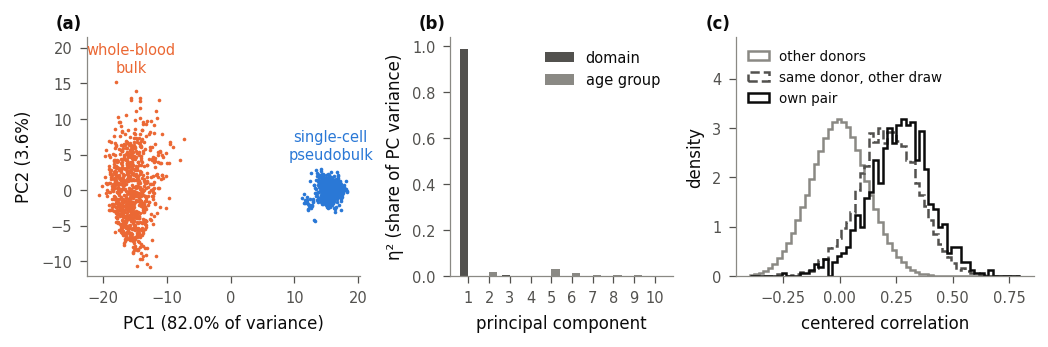

**The gap between single-cell pseudobulk and whole-blood bulk lies on one axis, and pairing carries sample-level signal.** (a) The first two principal components (PCs) of a principal component analysis fit to the 1,672 panel profiles of both domains (836 paired samples from 96 donors in each). PC1 explains 82.0% of the variance and separates the domains completely. (b) η², the share of each of the top 10 PCs' variance explained by domain or by donor age group (young, 25–37 years, or older, 55–67 years). Domain explains 99.0% of PC1 and at most 0.4% of PCs 2–5; age group explains at most 2.9% of any of the top five. The domain silhouette on the top 10 PCs is 0.777. (c) Centered correlation between a single-cell profile and a bulk profile, after each domain's per-gene mean is removed, for a sample's own pair (n = 836), for other draws of the same donor, and for draws of other donors. The medians are 0.269, 0.214 and −0.003. A sample's own bulk profile is its best match among the 836 for 17.5% of samples (median rank 8). Most of the pairing signal is shared across a donor's draws, and a smaller part is specific to the draw.

In [24]:
# Figure 0.11: the domain gap on the panel. (a) PCA of both domains together; (b) eta^2 of domain and
# age group per PC; (c) centered correlation: own pair vs same donor's other draws vs other donors.
fig, ax = figure("double", 2.2, 1, 3, gridspec_kw={"width_ratios": [1.1, 0.9, 1.2]})
order = np.random.default_rng(0).permutation(len(pcs))
dom_lab = np.where(domain == 0, "single-cell", "bulk")
for name, key in [("single-cell", "sc"), ("bulk", "bulk")]:
    m = dom_lab[order] == name
    ax[0].scatter(*pcs[order][m, :2].T, s=3, color=DOMAIN[name], linewidths=0, rasterized=True)
    cluster = pcs[dom_lab == name, :2]   # label each cluster directly, above it
    ax[0].text(np.median(cluster[:, 0]), cluster[:, 1].max() + 1, LABELS[key].replace(" ", "\n", 1), color=DOMAIN[name],
               ha="center", va="bottom", fontsize=7)
ax[0].set(xlabel=f"PC1 ({gap['var_ratio'].iloc[0]:.1%} of variance)", ylabel=f"PC2 ({gap['var_ratio'].iloc[1]:.1%})")
ax[0].set_ylim(top=ax[0].get_ylim()[1] + 5)
x = np.arange(len(gap))
ax[1].bar(x - 0.2, gap["eta2_domain"], width=0.4, color=INK_2, label="domain")
ax[1].bar(x + 0.2, gap["eta2_age"], width=0.4, color=MUTED, label="age group")
ax[1].set_xticks(x, [p.removeprefix("PC") for p in gap.index])
ax[1].set(xlabel="principal component", ylabel="η² (share of PC variance)"); ax[1].legend(loc="upper right")
bins = np.linspace(-0.4, 0.8, 60)
ax[2].hist(others, bins=bins, density=True, histtype="step", color=MUTED, lw=1.2, label="other donors")
ax[2].hist(donor_other[~np.isnan(donor_other)], bins=bins, density=True, histtype="step", color=INK_2, lw=1.2, ls="--", label="same donor, other draw")
ax[2].hist(own, bins=bins, density=True, histtype="step", color=INK, lw=1.2, label="own pair")
ax[2].set(xlabel="centered correlation", ylabel="density", ylim=(0, ax[2].get_ylim()[1] * 1.45))
ax[2].legend(loc="upper left", handlelength=1.5, fontsize=6.5)
panel_labels(ax)
save_show(fig, FIG, "0.11_domain_gap")
show_caption("0.11_domain_gap")

The first PC explains 82.0% of the variance of the 1,672 profiles, and domain explains 99.0% of it (η² = 0.990). Age group explains none of it (η² = 0.000); its largest share of any of the top five PCs is 2.9%, on PC5. The domain silhouette on the top 10 PCs is 0.777, close to complete separation (figure 0.11a, b).

Pairing carries signal on top of this gap. After each domain's mean profile is removed, the median centered correlation between a single-cell profile and its own bulk partner is 0.269, against 0.214 for other draws of the same donor and −0.003 for draws of other donors (figure 0.11c). The own partner is the best of 836 bulk profiles for 17.5% of single-cell profiles, and its median partner rank is 8. Most of the pairing signal is therefore shared across a donor's draws, and a smaller part is specific to the draw.

### 4.8 Training halves

**The two donor-disjoint training halves are balanced in donors, draws and age mix.** In halving 0, half A has 33 donors and 288 draws (54.5% from older donors) and half B has 35 donors and 294 draws (52.7%). Halving 1 gives 35 donors and 291 draws (54.3%) and 33 donors and 291 draws (52.9%). The assignment of every training draw is written to `results/phase0/train_halves.csv`.

In [25]:
from dgm.data import HALVING_SEEDS, train_halves

pairs = load_pairs()
rows, assign = [], {"sample_id": pairs.sample_ids[pairs.idx("train")]}
for seed in HALVING_SEEDS:
    halves = train_halves(pairs, seed)
    lookup = {}
    for name, idx in zip("AB", halves):
        rows.append({"halving": seed, "half": name, "donors": len(set(pairs.donor_ids[idx])), "draws": len(idx),
                     "older donors": len(set(pairs.donor_ids[idx][pairs.age_group[idx] == 1])),
                     "older draws (%)": 100 * pairs.age_group[idx].mean()})
        lookup.update({s: name for s in pairs.sample_ids[idx]})
    assign[f"halving_{seed}"] = [lookup[s] for s in assign["sample_id"]]
halves_tab = pd.DataFrame(rows).set_index(["halving", "half"])
display(halves_tab.style.format({"older draws (%)": "{:.1f}"}))
pd.DataFrame(assign).to_csv(paths.results_dir(0) / "train_halves.csv", index=False)

### 4.9 Composition varies mostly between donors

**For each of the five main lineages, only 18.7–32.1% of the composition variance across the 836 draws lies within donors.**

In [26]:
comp = pd.DataFrame(pairs.composition, columns=pairs.l1_classes)
grp = comp.groupby(pairs.donor_ids)
within = ((comp - grp.transform("mean")) ** 2).sum()
total = ((comp - comp.mean()) ** 2).sum()
within_share = (within / total).rename("within-donor share of variance")
display(within_share.to_frame().T.style.format("{:.2f}"))
within_share.to_csv(paths.results_dir(0) / "composition_within_donor_variance.csv")

,T cell,Monocyte,B cell,NK cell,DC,Other
within-donor share of variance,0.21,0.32,0.21,0.19,0.32,0.58


The within-donor share is 20.8% for T, 32.1% for Mono, 21.4% for B, 18.7% for NK and 31.6% for DC, and 58.0% for the small Other class (`results/phase0/composition_within_donor_variance.csv`). Composition is thus largely a donor trait. A translator that recovers a donor's typical composition already explains most of its variance, and recovering the draw-to-draw part is the harder task. This matches the pairing result in §4.7, where most of the similarity between partners is shared with the donor's other draws.

## 5. Conclusions

- **The domain gap is mostly one axis.** The first PC of both domains together explains 82.0% of the variance, with η²(domain) = 0.990; the domain silhouette on the top 10 PCs is 0.777 (1,672 profiles, 836 per domain).
- **Pairing carries sample-level signal, mostly at the donor level.** The median centered correlation is 0.269 with the own partner, 0.214 with the same donor's other draws and −0.003 with other donors; the own partner's median rank is 8 of 836. Only 18.7–32.1% of the composition variance of the main lineages lies within donors.
- **Single-cell → bulk translation must generate granulocyte signal.** Five granulocyte genes are 2.26–2.77 log(1 + CP10k) units higher in whole-blood bulk than in PBMC pseudobulk, where they are nearly absent.
- **Composition is readable from both domains.** The best marker per lineage reaches ρ = 0.75–0.89 in pseudobulk and 0.45–0.75 in whole blood (836 pairs).
- **Quality control removed nothing.** All 2,586,999 cells, 868 single-cell samples and 836 bulk libraries passed, giving 836 pairs from 96 donors.

These statistics are descriptive and computed once on all 836 pairs; they carry no confidence intervals.

### Implications
- Because most of the gap lies on one axis, baselines that remove a per-gene domain shift are strong comparators, and realism has to be judged on structure beyond the first PC.
- Because most of the pairing signal is shared across a donor's draws, sample-level accuracy needs a within-donor measure as well as a between-sample one.
- Granulocyte expression has no counterpart in the single-cell input, so whether a single-cell → bulk translator reproduces it, and whether it varies across samples, is a separate question from accuracy on shared genes.
- Composition readouts restricted to the panel cannot use the canonical T-cell markers (CD3E, CD3D, TRAC). Bulk composition targets are PBMC-relative, so a bulk readout learns PBMC proportions from a profile that also contains granulocytes.

## 6. Limitations

- **One cohort.** All pairs come from one study, one single-cell protocol and one bulk protocol, so the gap measured here may not carry over to other cohorts or platforms.
- **PBMC against whole blood.** The two assays measure different cell populations. The composition targets $c^*$ describe only the mononuclear fraction, and nothing in the data measures granulocyte abundance directly.
- **Subsampled cells.** Each pseudobulk and composition is computed from at most 3,000 cells per sample, so rare classes (DC and Other) are estimated with more sampling noise than the full sample would give.
- **One pseudobulk per sample.** Each draw gives one single-cell profile; we did not resample cells to form several pseudobulks per sample.
- **Provider labels and filtering.** Composition relies on the provider's AIFI_L1 labels as given, and the provider's prior filtering means our quality-control thresholds removed no cells. We did not explore other thresholds.
- **Two separated age groups.** No donor is aged 38–54, so age enters only as a two-group label.
- **Descriptive statistics without uncertainty.** The domain-gap statistics are computed once on all 836 pairs, without bootstrap intervals.

## 7. Reproducibility

**Inputs.** Rebuild the eight single-cell subsample files from the AIFI portal files with `python scripts/make_slims.py <portal directory>`, and place the whole-blood bulk file next to them in `data/raw/soundlife/` (README, "Data"). The notebook checks all nine files against pinned SHA-256 checksums before using them.

**Runtime.** A first run hashes about 28 GB of raw files (1–2 minutes) and processes the single-cell files (about 10 minutes). Later runs reuse the caches below.

**Determinism.** `dgm.notebook.setup` seeds the random generators (seed 0) and prints the commit and notebook source hash in the first code cell. The donor split uses a fixed seed (`SPLIT_SEED`), panel ties are broken by gene symbol, the cell-level UMAP and the leakage check use seed 0, and `dgm.data.train_halves` uses the halving seeds 0 and 1. All steps run on the CPU.

**Caches.** The processed files in `data/processed/` are keyed on their parameters, the raw-file checksums and a hash of the source of the cell that builds them (`this_cell_sha`), so editing that cell rebuilds them. The raw-file checksums are cached in `data/processed/raw_checksums.json` by file size and modification time. Set `FORCE = True` in the setup cell to rebuild every cache.

**Outputs.**

| File | Contents |
|---|---|
| `data/processed/sc_cell_qc.h5ad` | one row per subsampled cell: quality-control metrics, pass flag, AIFI_L1 and AIFI_L2 labels |
| `data/processed/sc_pseudobulk_counts.h5ad` | single-cell pseudobulk raw counts (868 samples × 33,514 genes), with sample metadata and the 9-class composition |
| `data/processed/sc_cell_sample.h5ad` | 60 passing cells per sample with raw counts and the cell-level UMAP (diagnostic) |
| `data/processed/bulk_counts.h5ad` | bulk raw counts per kit (836 kits × 58,302 genes), with library quality-control metrics |
| `data/processed/soundlife_pairs.npz` | the model-ready pairs: panel profiles of both domains (836 × 5,000), 6-class composition, sample and donor identifiers, age, age group and split; written and checked by `dgm.data.save_pairs` |
| `results/phase0/train_halves.csv` | the half (A or B) of every training draw under halvings 0 and 1 |
| `results/phase0/composition_within_donor_variance.csv` | the within-donor share of composition variance per class |
| `results/phase0/figures/` | figures 0.1–0.3 and 0.5 and 0.7–0.11 (PNG and PDF) and their captions (`captions.md`) |

Later phases load the pairs with

```python
from dgm.data import load_pairs
pairs = load_pairs()                      # checked on load
x_sc, x_bulk = pairs.x_sc, pairs.x_bulk   # (836, 5000) log(1 + CP10k)
train = pairs.idx("train")
```

## References

- Gong, Q., Sharma, M., Glass, M. C. et al. Multi-omic profiling reveals age-related immune dynamics in healthy adults. *Nature* 648, 696–706 (2025). doi:10.1038/s41586-025-09686-5.
- Wolf, F. A., Angerer, P. & Theis, F. J. SCANPY: large-scale single-cell gene expression data analysis. *Genome Biology* 19, 15 (2018).